<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/heeyeon/advanced/heeyeon/session03/assignment_image%26sequence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 딥러닝 과제 - 이미지 분류 & 시퀀스 모델

이번 과제는 두 가지 큰 주제로 구성됩니다.

| 파트 | 주제 | 프레임워크 |
|:---:|:---|:---:|
| PART 1 | 이진 분류 : Cats vs Dogs | PyTorch |
| PART 2 | 다중 분류 : CIFAR-10 (전이학습) | PyTorch |
| PART 3 | LSTM 텍스트 감성 분석 (NSMC) + 🎯 모델 속이기 챌린지 | PyTorch |
| PART 4 | LSTM 시계열 기온 예측 (예나 기후) | PyTorch |
| PART 5 | Character-Level Seq2Seq + 🎯 변환 규칙 설계 | PyTorch |

> 💡 **파일 안내** - 드라이브에 옮겨두지 않았다면 미리 옮겨두시길!
> - `jena_climate_2009_2016.csv` : PART 4 기온 예측에 사용
> - `words.txt` : PART 5 Seq2Seq에 사용

---

# ⚙️ PART 0. 공통 환경 설정

## 0-1. 라이브러리 설치 및 임포트

이 노트북은 모든 파트에서 **PyTorch**를 사용합니다.

> Colab에는 PyTorch가 설치되어 있어 별도 설치 없이 바로 `import`할 수 있습니다.

In [1]:
!pip install albumentations datasets -q

# ── PyTorch 관련 ──────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models, datasets
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import random

import pandas as pd
import copy

# ── 재현성을 위한 시드 고정 ────────────────────────────────────
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# ── 사용 디바이스 확인 ──────────────────────────────────────────
# GPU가 있으면 'cuda', 없으면 'cpu' 로 자동 설정됩니다
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("PyTorch 사용 장치:", device)

PyTorch 사용 장치: cuda


## 0-2. 한글 폰트 설정

그래프 제목 등의 한글이 깨지지 않도록 운영체제에 맞는 폰트를 설정합니다.
Colab에서는 나눔고딕을 자동으로 설치하고, Windows에서는 맑은 고딕을 사용합니다. Colab과 VS Code 모두 그대로 실행하면 됩니다.

In [2]:
import os
import platform
import subprocess
import matplotlib.font_manager as fm

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'   # 맑은 고딕
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'     # macOS
else:
    # Colab(리눅스): 나눔고딕이 없으면 설치한 뒤 등록합니다
    font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(font_path):
        subprocess.run(['apt-get', '-qq', 'install', 'fonts-nanum'], check=False)
    if os.path.exists(font_path):
        fm.fontManager.addfont(font_path)
        plt.rcParams['font.family'] = 'NanumGothic'
    else:
        print('⚠️ 나눔고딕을 설치하지 못했습니다. 그래프의 한글이 깨질 수 있어요.')

plt.rcParams['axes.unicode_minus'] = False   # 마이너스(-) 기호 깨짐 방지
print("폰트 설정 완료:", plt.rcParams['font.family'])

폰트 설정 완료: ['NanumGothic']


---

# ✍️ 이론 확인 : CNN

> **MLP로 이미지를 처리할 때의 한계 세 가지는?**
> - 답1: 공간 구조 손실. 일렬로 펴며 위치 정보가 사라진다
> - 답2: 파라미터 폭발. 파라미터 수가 매우 많아진다.
> - 답3: 위치 변화에 취약. 같은 이미지가 조금만 달라져도 다른 걸 인식한다

> **CNN은 어떤 구조로 파라미터 폭발 문제를 해결하나요?**
> - 답: 그래서 cnn은 각 뉴련을 작은 일부 영역만 보게 만들어서, 같은 필터를 이미지 전체에 반복 적용한다.

> **Pooling의 장점과 단점은?**
> - 장점: 연산량과 파라미터를 크게 감소시킨다
> - 단점: 버려진 세부 정보가 손실된다.

아래 코드를 실행해 padding과 stride에 따라 Feature Map 크기가 어떻게 달라지는지 확인한 뒤 답해 주세요.

In [3]:
# 입력: 32×32 흑백 이미지 1장, 필터 크기는 3×3으로 고정
dummy_image = torch.rand(1, 1, 32, 32)

for padding, stride in [(0, 1), (1, 1), (1, 2)]:
    conv = nn.Conv2d(1, 8, kernel_size=3, padding=padding, stride=stride)
    print(f"padding={padding}, stride={stride} → Feature Map 크기: {conv(dummy_image).shape[2:]}")

padding=0, stride=1 → Feature Map 크기: torch.Size([30, 30])
padding=1, stride=1 → Feature Map 크기: torch.Size([32, 32])
padding=1, stride=2 → Feature Map 크기: torch.Size([16, 16])


> **padding을 쓰는 이유는 무엇인가요?**
> - 답: 테두리에 덧대서 입력 출력 크기를 유지한다

> **stride를 키우면 어떻게 되나요?**
> - 답: 필터가 더 많이 건너뛰어서 featuremap 크기가 줄어든다, 따라서 연산량이 줄어든다.


---

# 📸 PART 1. 이진 분류 : Cats 🐱 vs Dogs 🐶

Microsoft의 **Cats vs Dogs** 데이터셋(~25,000장)으로 이진 분류 CNN을 처음부터 직접 구현합니다.

## 🔑 핵심 개념

### CNN (합성곱 신경망)이란?

이미지를 그냥 1차원으로 펼쳐서 FC에 넣으면 **위치 정보**가 사라집니다.
CNN은 작은 **필터(커널)** 를 이미지 위에 슬라이딩하면서 지역 패턴을 감지합니다.

```
Conv 레이어  : 필터가 이미지를 훑으며 엣지, 텍스처 등의 특징을 추출
ReLU        : 음수를 0으로 만드는 활성화 함수 (비선형성 추가)
MaxPooling  : 특징 맵 크기를 절반으로 줄여 계산량 감소 + 위치 불변성 확보
```

### 이진 분류와 다중 분류의 차이

| 항목 | 이진 분류 (이번 파트) | 다중 분류 (PART 2) |
|:---:|:---:|:---:|
| 출력 노드 수 | **1개** | 클래스 수 |
| 활성화 함수 | **Sigmoid** → 0~1 확률 | Softmax → 합이 1 |
| 손실 함수 | **BCELoss** | CrossEntropyLoss |
| 예측 기준 | 출력 ≥ 0.5 → 양성(Dog) | argmax |

> 💡 `BCEWithLogitsLoss` = Sigmoid + BCELoss를 수치 안정성 있게 합친 것
> 이 경우 모델 마지막에 Sigmoid를 **붙이지 않아도** 됩니다!

### 데이터 증강 (Data Augmentation)

같은 이미지를 매 에폭마다 **다른 방식으로 변형**해서 학습합니다.
- 모델이 다양한 패턴을 보게 되어 **과적합이 줄어들고** 일반화 성능이 높아집니다.
- 예: 고양이를 뒤집거나 회전해도 여전히 고양이여야 합니다.

---

## 1-1. 데이터 로드

In [4]:
from datasets import load_dataset
from collections import Counter

print("📥 데이터셋 로딩 중... (처음 실행 시 다운로드로 시간이 걸립니다)")
dataset = load_dataset("microsoft/cats_vs_dogs")
print("완료:", dataset)

# ── Train / Val / Test 분할 ────────────────────────────────────
# 전체의 20%를 test로, 나머지 80%의 20%를 val로 사용합니다
train_test = dataset['train'].train_test_split(test_size=0.2, seed=42)
train_val  = train_test['train'].train_test_split(test_size=0.2, seed=42)
train_hf   = train_val['train']
val_hf     = train_val['test']
test_hf    = train_test['test']
print(f"Train: {len(train_hf)}장  |  Val: {len(val_hf)}장  |  Test: {len(test_hf)}장")

📥 데이터셋 로딩 중... (처음 실행 시 다운로드로 시간이 걸립니다)


README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

완료: DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 23410
    })
})
Train: 14982장  |  Val: 3746장  |  Test: 4682장


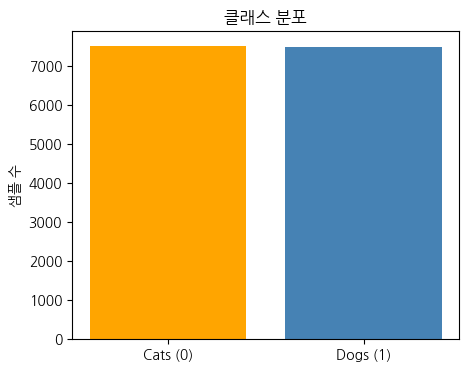

Cats: 7500장  |  Dogs: 7482장


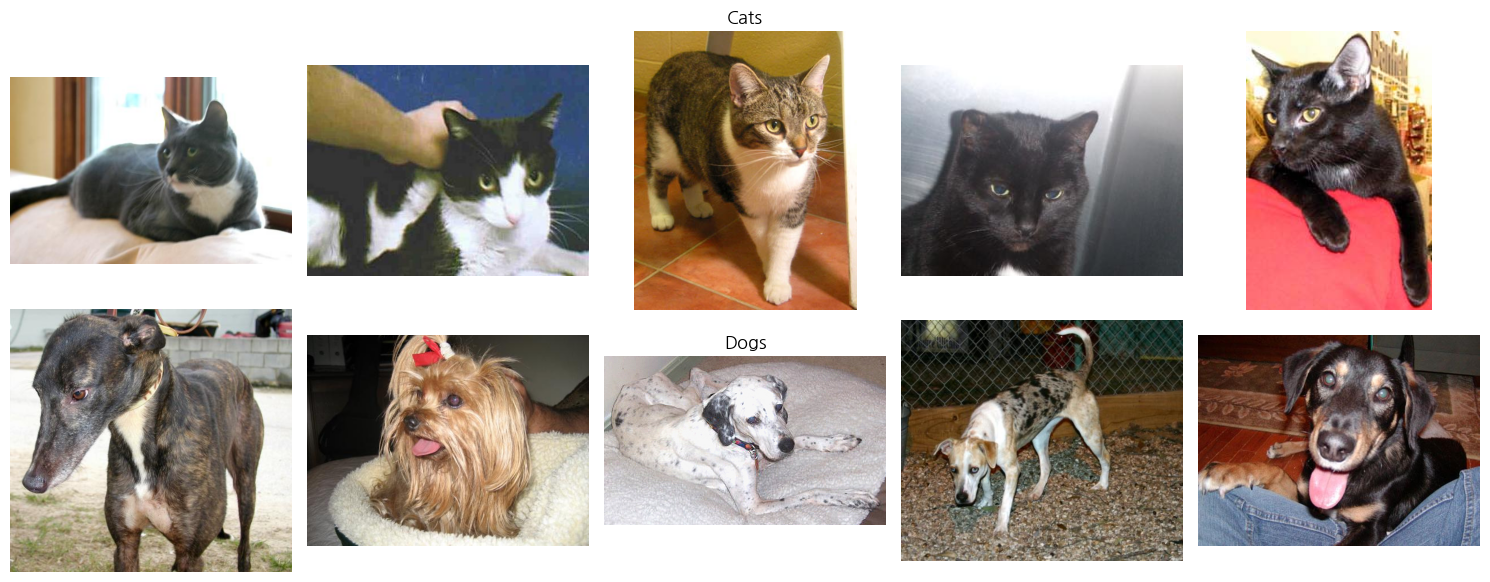

In [6]:
# ── 클래스 분포 확인 ────────────────────────────────────────────
# 두 클래스의 샘플 수가 비슷한지 확인합니다 (불균형이 심하면 정확도만으로 평가 금물!)
labels = [item['labels'] for item in train_hf]
cnt    = Counter(labels)
plt.figure(figsize=(5, 4))
plt.bar(['Cats (0)', 'Dogs (1)'], [cnt[0], cnt[1]], color=['orange', 'steelblue'])
plt.title('클래스 분포'); plt.ylabel('샘플 수'); plt.show()
print(f"Cats: {cnt[0]}장  |  Dogs: {cnt[1]}장")

# ── 샘플 이미지 시각화 ──────────────────────────────────────────
cats, dogs = [], []
for item in train_hf:
    if item['labels'] == 0 and len(cats) < 5: cats.append(item['image'])
    elif item['labels'] == 1 and len(dogs) < 5: dogs.append(item['image'])
    if len(cats) >= 5 and len(dogs) >= 5: break

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    axes[0, i].imshow(cats[i]); axes[0, i].axis('off')
    axes[1, i].imshow(dogs[i]); axes[1, i].axis('off')
axes[0, 2].set_title('Cats', fontsize=13)
axes[1, 2].set_title('Dogs', fontsize=13)
plt.tight_layout(); plt.show()

## 1-2. 데이터 전처리 및 증강

### albumentations vs torchvision transforms

| | albumentations | torchvision transforms |
|:---:|:---:|:---:|
| 속도 | 빠름 | 보통 |
| 기능 | 매우 다양 | 기본적인 것만 |
| 입력 | numpy array | PIL Image |

---
#### 아래에서 적용하는 증강 기법들:
1. 기본 전처리

- A.Resize(h, w): 이미지 전체 크기를 h x w 크기로 변환
- A.CenterCrop(h, w): 이미지 중앙을 기준으로 h x w만큼 잘라냄

2. 데이터 증강 (Data Augmentation)

- A.HorizontalFlip(p): p의 확률로 이미지를 좌우 반전 (고양이/개는 방향이 바뀌어도 같은 동물)
- A.Rotate(limit, p): limit(-x ~ +x)의 각도 내에서, p의 확률로 이미지 랜덤 회전

3. 색상 변환

- A.ColorJitter(brightness, contrast, saturation, hue, p): 밝기(brightness), 대비(contrast), 채도(saturation), 색조(hue)를 p의 확률로 랜덤 변환
- A.ToGray(p): p의 확률로 이미지를 흑백으로 변환

4. 정규화 (Normalization)

- A.Normalize(mean, std): ImageNet 평균/표준편차로 정규화 → 전이학습 시 필수!


In [7]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 공통 mean, std 값
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

# ── 학습용 transform : 증강 O ────────────────────────────────
train_transform = A.Compose([
    A.Resize(256, 256),                                      # 256×256으로 변환
    A.HorizontalFlip(p=0.5),                                 # 50% 확률로 좌우 반전
    A.Rotate(limit=30, p=0.5),                               # ±30도 이내 회전
    A.ColorJitter(brightness=0.2, contrast=0.2,
                  saturation=0.2, hue=0.1, p=0.5),          # 50% 확률로 색상 변환
    A.Normalize(mean=mean, std=std),                         # 픽셀값 정규화
    ToTensorV2()                                             # numpy → PyTorch Tensor
])

# ── 검증/테스트용 transform : 증강 X (크기 조정 + 정규화만) ─────
val_test_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=mean, std=std),
    ToTensorV2()
])
print("Transform 정의 완료!")

Transform 정의 완료!


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np

class CatsDogsDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset   = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item  = self.dataset[idx]
        image = item['image']
        label = item['labels']

        # PIL Image → numpy array (RGB 보장)
        try:
            image = np.array(image.convert('RGB'))
        except Exception as e:
            print(f"이미지 로딩 오류 (idx={idx}): {e}")
            image = np.zeros((256, 256, 3), dtype=np.uint8)

        if self.transform:
            image = self.transform(image=image)['image']

        label = torch.tensor(label, dtype=torch.float32)
        return image, label

train_ds = CatsDogsDataset(train_hf, train_transform)
val_ds   = CatsDogsDataset(val_hf,   val_test_transform)
test_ds  = CatsDogsDataset(test_hf,  val_test_transform)

BATCH_SIZE = 32

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train batches: {len(train_loader)}")
print(f"Val   batches: {len(val_loader)}")
print(f"Test  batches: {len(test_loader)}")

Train batches: 469
Val   batches: 118
Test  batches: 147


In [12]:
import torch.nn as nn
import torch.nn.functional as F

class AlexNetBinary(nn.Module):
    def __init__(self):
        super(AlexNetBinary, self).__init__()

        # ── 특징 추출기 (Feature Extractor) ─────────────────────
        # AlexNet 구조: Conv → ReLU → MaxPool 반복
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # 256×256 입력 기준으로 features 출력 크기 자동 계산
        # Conv 레이어를 통과한 뒤 정확한 크기를 모르니까 실제로 한 번 통과시켜서 크기를 재는 것
        dummy = torch.randn(1, 3, 256, 256)
        output_size = self.features(dummy).view(1, -1).size(1)

        # ── 분류기 (Classifier) ──────────────────────────────────
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(output_size, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, 1),             # 이진 분류 → 출력 1개
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)          # Flatten
        x = self.classifier(x)
        return x

model_catdog = AlexNetBinary()
total_params = sum(p.numel() for p in model_catdog.parameters())
print(f"전체 파라미터 수: {total_params:,}")

전체 파라미터 수: 70,639,425


### 💡 PyTorch의 모드 전환 함수: `model.train()`과 `model.eval()`

PyTorch 모델에는 **학습 모드**와 **평가 모드**가 있고, 지금 어떤 모드인지에 따라 일부 층이 다르게 동작합니다. 그래서 학습이나 평가를 시작하기 전에 아래 **모드 전환 함수**로 모드를 직접 바꿔 줘야 합니다.

| 함수 | 모드 | 언제 호출하나 |
|---|---|---|
| `model.train()` | 학습 모드 | train 데이터로 가중치를 학습할 때 |
| `model.eval()` | 평가 모드 | validation, test 데이터로 성능을 평가할 때 |

**왜 `model.test()`가 아니라 `model.eval()`일까요?**
`model.eval()`은 "테스트 데이터로 평가해라"가 아니라 **"모델을 평가 모드로 바꿔라"** 라는 뜻입니다. 검증이든 테스트든 모델 입장에서는 똑같이 학습 없이 평가만 하는 상황이라, 둘 다 `eval()`을 씁니다. `model.test()`라는 함수는 없어서 호출하면 에러가 납니다.

**모드에 따라 달라지는 층**
- **Dropout** (위 `AlexNetBinary`에 있어요): 학습 때는 뉴런을 무작위로 끄지만, 평가 때는 모두 사용합니다.
- **BatchNorm** (Part 2의 ResNet에 있어요): 학습 때는 현재 배치의 통계를 쓰고 갱신하지만, 평가 때는 저장해 둔 통계만 씁니다.

> ⚠️ `torch.no_grad()`와는 역할이 다릅니다. `eval()`은 위 층들의 동작을 바꿀 뿐 기울기 계산을 끄지 않습니다. 기울기 계산을 끄는 것은 `no_grad()`라서, 아래 `validate` 함수처럼 둘을 함께 씁니다.

아래 코드의 빈칸을 채울 때 함수마다 어떤 모드가 필요한지 생각해 보세요!

In [15]:
from tqdm.auto import tqdm

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()                                        # 학습 모드
    running_loss = 0.0
    correct = 0
    total   = 0

    pbar = tqdm(train_loader, desc='Training', leave=False)

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)          # (batch, 1) 형태로 맞춤

        outputs = model(images)
        loss    = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total   += labels.size(0)
        correct += (predicted == labels).sum().item()

        pbar.set_postfix({'loss': f'{running_loss/total:.4f}',
                          'acc':  f'{correct/total:.4f}'})

    return running_loss / total, correct / total


def validate(model, val_loader, criterion, device):
    model.eval()                                         # 평가 모드
    running_loss = 0.0
    correct = 0
    total   = 0

    pbar = tqdm(val_loader, desc='Validation', leave=False)

    with torch.no_grad():
        for images, labels in pbar:
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            outputs = model(images)
            loss    = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()

            pbar.set_postfix({'loss': f'{running_loss/total:.4f}',
                              'acc':  f'{correct/total:.4f}'})

    return running_loss / total, correct / total

print("train_one_epoch(), validate() 함수 정의 완료")

train_one_epoch(), validate() 함수 정의 완료


## 1-5. 모델 학습

**Best 모델 저장**: 검증 정확도가 가장 높았던 에폭의 가중치를 저장해 두고, 나중에 불러와서 평가합니다.

### 이 마크다운을 꼭 읽어주세요
아래 이미지처럼 뜨지 않는다면!!! CPU를 사용하고 있는 것입니다!!!!! cpu쓰면 1시간 넘게 걸려요!!!!!
정상적으로 돌린다면 Epoch1이 2분 안에 돌아가야 합니다!\
꼭 확인하고 기다려주세요!!!

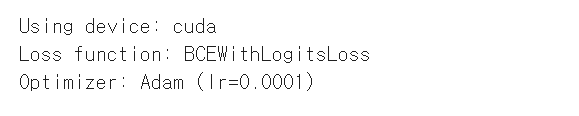

**참고: 아래 코드 전체 돌아가는 데에는 약 20분 정도 소요됩니다!**

In [16]:
device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model_catdog = model_catdog.to(device)

criterion = nn.BCEWithLogitsLoss()                          # 이진 분류 손실
optimizer = torch.optim.Adam(model_catdog.parameters(), lr=0.0001)

print("Loss function: BCEWithLogitsLoss")
print("Optimizer: Adam (lr=0.0001)")

NUM_EPOCHS = 10
train_losses, train_accs = [], []
val_losses,   val_accs   = [], []

best_val_acc = 0.0 # Initialize best validation accuracy

print("\n학습 시작!\n")

for epoch in tqdm(range(NUM_EPOCHS), desc='Overall Progress'):
    train_loss, train_acc = train_one_epoch(model_catdog, train_loader, criterion, optimizer, device)
    val_loss,   val_acc   = validate(model_catdog, val_loader, criterion, device)

    train_losses.append(train_loss); train_accs.append(train_acc)
    val_losses.append(val_loss);     val_accs.append(val_acc)

    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}%")
    print(f"  Val   Loss: {val_loss:.4f},   Val   Acc: {val_acc*100:.2f}%")

    # Best 모델 저장 로직 추가
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_catdog.state_dict(), 'catdog_best.pt')
        print(f"  ⭐ Best 모델 저장! (Val Acc: {best_val_acc*100:.2f}%)")


print("\n학습 완료!")
print(f"Best Train Acc: {max(train_accs)*100:.2f}%  (Epoch {train_accs.index(max(train_accs))+1})")
print(f"Best Val   Acc: {max(val_accs)*100:.2f}%  (Epoch {val_accs.index(max(val_accs))+1})")

Using device: cuda
Loss function: BCEWithLogitsLoss
Optimizer: Adam (lr=0.0001)

학습 시작!



Overall Progress:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/469 [00:00<?, ?it/s]

Validation:   0%|          | 0/118 [00:00<?, ?it/s]


Epoch [1/10]
  Train Loss: 0.6560, Train Acc: 60.67%
  Val   Loss: 0.6108,   Val   Acc: 65.83%
  ⭐ Best 모델 저장! (Val Acc: 65.83%)


Training:   0%|          | 0/469 [00:00<?, ?it/s]

... (22 outputs left out)


Epoch [9/10]
  Train Loss: 0.2591, Train Acc: 88.65%
  Val   Loss: 0.3044,   Val   Acc: 87.16%
  ⭐ Best 모델 저장! (Val Acc: 87.16%)


Training:   0%|          | 0/469 [00:00<?, ?it/s]

Validation:   0%|          | 0/118 [00:00<?, ?it/s]


Epoch [10/10]
  Train Loss: 0.2357, Train Acc: 90.19%
  Val   Loss: 0.2595,   Val   Acc: 89.27%
  ⭐ Best 모델 저장! (Val Acc: 89.27%)

학습 완료!
Best Train Acc: 90.19%  (Epoch 10)
Best Val   Acc: 89.27%  (Epoch 10)


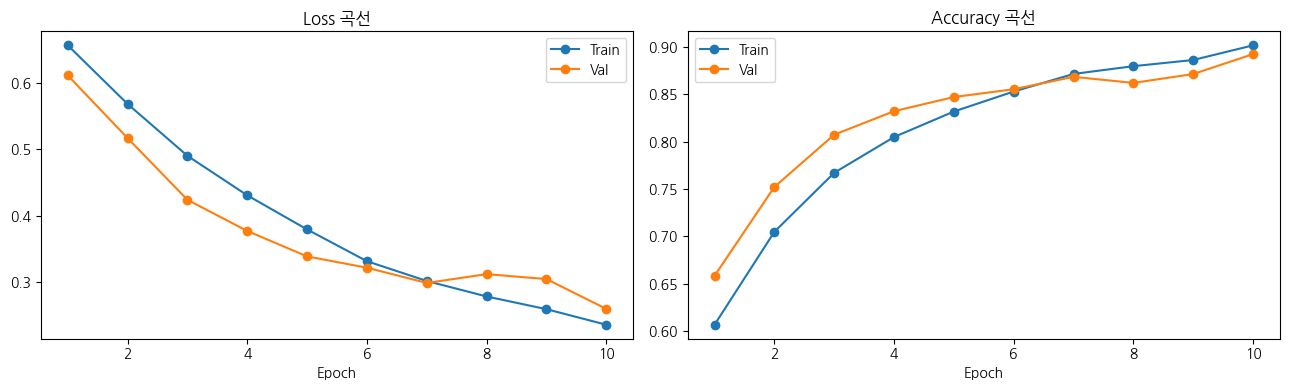

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, len(train_losses)+1)

axes[0].plot(ep, train_losses, marker='o', label='Train')
axes[0].plot(ep, val_losses,   marker='o', label='Val')
axes[0].set_title('Loss 곡선'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(ep, train_accs, marker='o', label='Train')
axes[1].plot(ep, val_accs,   marker='o', label='Val')
axes[1].set_title('Accuracy 곡선'); axes[1].set_xlabel('Epoch'); axes[1].legend()

plt.tight_layout(); plt.show()

## 1-6. 테스트 평가 & 예측 시각화

Best 모델을 불러와서 테스트 셋으로 최종 성능을 측정합니다.

Validation:   0%|          | 0/147 [00:00<?, ?it/s]

🎯 테스트 Loss: 0.2341  |  테스트 Accuracy: 0.9045


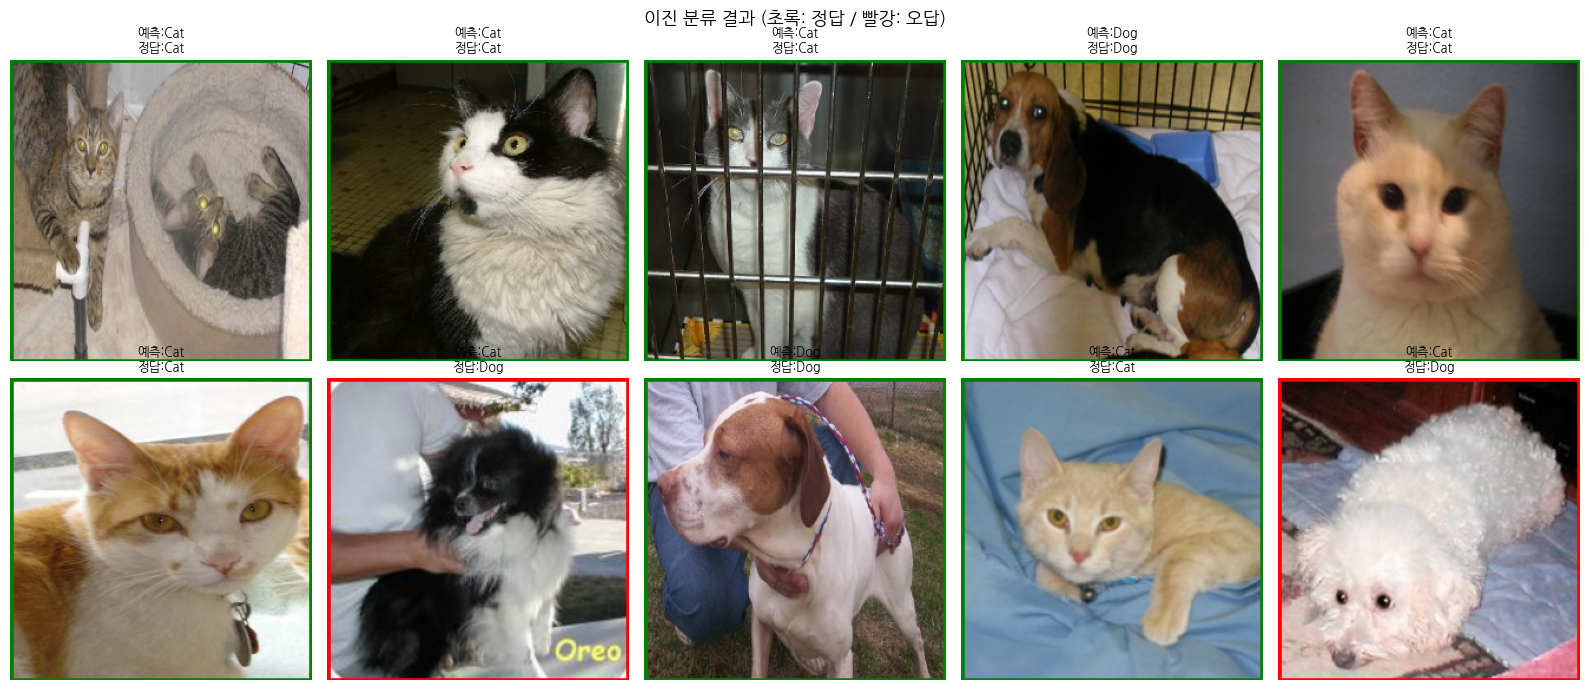

In [19]:
# ── Best 모델 불러오기 ──────────────────────────────────────────
model_catdog.load_state_dict(torch.load('catdog_best.pt', map_location=device))
test_loss, test_acc = validate(model_catdog, test_loader, criterion, device)
print(f"🎯 테스트 Loss: {test_loss:.4f}  |  테스트 Accuracy: {test_acc:.4f}")

# ── 10개 랜덤 예측 시각화 ────────────────────────────────────────
model_catdog.eval()
classes = ['Cat', 'Dog']
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.ravel()

for i, idx in enumerate(random.sample(range(len(test_ds)), 10)):
    img_t, label = test_ds[idx]
    with torch.no_grad():
        pred = int((torch.sigmoid(model_catdog(img_t.unsqueeze(0).to(device))) >= 0.5).item())

    # 역정규화 : 시각화를 위해 정규화 전 범위(0~1)로 복원
    img_np = img_t.permute(1,2,0).numpy()
    img_np = np.clip(img_np * [0.229,0.224,0.225] + [0.485,0.456,0.406], 0, 1)

    axes[i].imshow(img_np); axes[i].axis('off')
    axes[i].set_title(f"예측:{classes[pred]}\n정답:{classes[int(label)]}", fontsize=9)

    # 정답이면 초록, 틀리면 빨간 테두리
    color = 'green' if pred == int(label) else 'red'
    axes[i].add_patch(patches.Rectangle((0,0), img_np.shape[1], img_np.shape[0],
                                         linewidth=4, edgecolor=color, facecolor='none'))
plt.suptitle('이진 분류 결과 (초록: 정답 / 빨강: 오답)', fontsize=13)
plt.tight_layout(); plt.show()

---

# ✍️ 이론 확인 : CNN 아키텍처

> **ResNet이 층을 아주 깊게 쌓아도 학습이 되는 이유는 무엇인가요?**
> - 답: 잔차 연결로 기울기 소실 문제가 덜 해진다. 층을 깊게 쌓아도 성능이 안 떨어진다.

---

# 🎨 PART 2. 다중 분류 : CIFAR-10 (전이학습)

**CIFAR-10** : 32×32 크기의 이미지 60,000장 (10개 클래스)

10개 클래스 : 비행기, 자동차, 새, 고양이, 사슴, 개, 개구리, 말, 배, 트럭

## 🔑 핵심 개념: 전이학습 (Transfer Learning)

전이학습이란, **누군가 이미 열심히 공부해놓은 노트를 빌려서** 우리 문제에 맞게 조금만 고쳐 쓰는 방법입니다.
(심화세션 6차시인 AI 최적화 & 엔지니어링 세션에서 더 자세하게 배워요!)

우리가 빌려올 모델은 바로 **ResNet18** 이라는 모델입니다.
ResNet18은 **ImageNet** 이라는 대규모 데이터셋(약 140만 장, 1000개 클래스)으로 미리 학습된 모델로,
이미 수많은 이미지를 보며 **선, 곡선, 텍스처, 형태** 같은 특징을 잘 잡아내도록 훈련되어 있습니다.

> 💡 **ImageNet** : 사람, 자동차, 동물 등 1000가지 물체가 담긴 초대형 이미지 데이터셋입니다.
> 이 데이터로 학습된 모델은 이미지의 다양한 특징을 잘 추출할 수 있어서,
> **다른 이미지 문제에도 그대로 활용**할 수 있습니다.

### 이 모델이 세션에서 배운 ResNet이에요!

**ResNet18**은 세션에서 배운 **ResNet(2015)** 중 18층짜리 모델입니다. 직접 구현하는 대신, 이미 학습된 모델을 불러와서 사용합니다.

- **핵심 아이디어** : Residual 연결(skip connection)로 입력 $x$를 출력에 그대로 더해 줍니다. → $\text{출력} = F(x) + x$
- **효과** : 이 연결 덕분에 매우 깊은 네트워크도 학습할 수 있습니다.
- **구조** : 입력 Conv → `layer1` ~ `layer4` (Residual 블록을 쌓은 부분) → 평균 풀링 → `fc` (분류기)

모델을 불러온 뒤, 아래 2-2에서 Residual 블록을 직접 확인해 봅니다.

### 왜 전이학습이 유리한가?
- ResNet18이 ImageNet에서 이미 학습한 **이미지 특징 추출 능력**을 그대로 가져옵니다!
- 이 능력은 CIFAR-10에서도 그대로 유효합니다!
- 마지막 분류기 부분만 CIFAR-10에 맞게 교체하면 **적은 데이터, 짧은 시간**으로 높은 성능을 낼 수 있습니다.

### 어느 레이어를 재학습할까?

```
ResNet18
  ├── layer1 ~ layer3  : 동결 (requires_grad=False) → ImageNet 특징 재사용
  ├── layer4            : 재학습 → 고수준 특징을 CIFAR-10에 맞게 미세조정
  └── fc (분류기)        : 교체 (1000→10클래스)
```

> 앞쪽 레이어는 범용적인 저수준 특징(선, 곡선 등)을 학습하고,
> 뒤쪽 레이어일수록 데이터셋에 특화된 고수준 특징을 학습합니다.
> 그래서 뒤쪽만 재학습해도 충분히 좋은 성능이 나옵니다.

---

## 2-1. 데이터 로드 (CIFAR-10)
### 이미지 데이터 전처리 기본 코드 참고
- **🔄 RandomHorizontalFlip (좌우 반전)** -
이미지를 50% 확률로 좌우로 뒤집습니다.  
비행기나 자동차는 방향이 바뀌어도 같은 클래스이므로, 반전된 이미지도 유효한 학습 데이터가 됩니다.
- **✂️ RandomCrop (패딩 후 랜덤 크롭)** -
이미지 상하좌우에 8픽셀씩 0으로 패딩한 뒤, 원래 크기(64×64)로 랜덤하게 잘라냅니다.  
이미지를 살짝 이동시키는 효과로, 물체가 항상 중앙에 있지 않아도 인식하도록 학습시킵니다.
- **🎨 ColorJitter (색상 변화)** -
밝기(brightness), 대비(contrast), 채도(saturation)를 무작위로 조금씩 변화시킵니다.  
조명 환경이 달라져도 같은 물체를 인식할 수 있도록 색상 불변성을 학습시킵니다.

| 파라미터 | 의미 | 설정값 |
|:---:|:---|:---:|
| brightness | 이미지 밝기 변화 범위 | ±0.2 |
| contrast | 밝고 어두운 차이 변화 범위 | ±0.2 |
| saturation | 색의 선명도 변화 범위 | ±0.2 |

In [20]:
# ── CIFAR-10 전처리 ──────────────────────────────────────────────
# ResNet은 원래 224×224 입력을 기대하지만, 64×64로 업스케일해도 충분합니다
cifar_transform_train = transforms.Compose([
    transforms.Resize(64),
    transforms.RandomHorizontalFlip(),              # 좌우 반전
    transforms.RandomCrop(64, padding=8),           # 패딩 후 랜덤 크롭
    transforms.ColorJitter(0.2, 0.2, 0.2),         # 색상 변화
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],   # CIFAR-10 전용 정규화값
                         [0.2470,0.2435,0.2616])
])
cifar_transform_val = transforms.Compose([
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2470,0.2435,0.2616])
])

# ── 데이터 로드 (Hugging Face datasets 사용) ─────────────────────
# 기존 torchvision.datasets.CIFAR10(download=True) 방식은 Colab에서
# 토론토 서버 접속이 차단되어 504 Timeout 오류가 자주 발생합니다.
# Hugging Face 'datasets' 라이브러리를 이용하면 안정적으로 다운로드됩니다.
from datasets import load_dataset
from torch.utils.data import Dataset as TorchDataset

class CIFAR10HFDataset(TorchDataset):
    """Hugging Face CIFAR-10을 PyTorch Dataset으로 감싸는 클래스"""
    def __init__(self, hf_split, transform=None):
        self.data      = hf_split
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item  = self.data[idx]
        image = item['img'].convert('RGB')          # PIL Image
        label = item['label']                       # 정수 레이블
        if self.transform:
            image = self.transform(image)
        return image, label

print("📥 CIFAR-10 로딩 중... (처음 실행 시 다운로드로 시간이 걸립니다)")
cifar_hf = load_dataset("uoft-cs/cifar10")         # 공식 HF CIFAR-10
print("완료!")

# ── Train(40,000) / Val(10,000) / Test(10,000) 분리 ──────────────
val_size   = int(len(cifar_hf['train']) * 0.2)     # 10,000장
train_size = len(cifar_hf['train']) - val_size      # 40,000장

cifar_train_full_hf = cifar_hf['train']
train_val_split = cifar_train_full_hf.train_test_split(
    test_size=0.2, seed=42)

cifar_train_ds = CIFAR10HFDataset(train_val_split['train'], cifar_transform_train)
cifar_val_ds   = CIFAR10HFDataset(train_val_split['test'],  cifar_transform_val)
cifar_test_ds  = CIFAR10HFDataset(cifar_hf['test'],         cifar_transform_val)

cifar_train_loader = DataLoader(cifar_train_ds, batch_size=128, shuffle=True,  num_workers=2)
cifar_val_loader   = DataLoader(cifar_val_ds,   batch_size=128, shuffle=False, num_workers=2)
cifar_test_loader  = DataLoader(cifar_test_ds,  batch_size=128, shuffle=False, num_workers=2)

CIFAR_CLASSES = ['비행기','자동차','새','고양이','사슴','개','개구리','말','배','트럭']
print(f"Train:{len(cifar_train_ds)} | Val:{len(cifar_val_ds)} | Test:{len(cifar_test_ds)}")

📥 CIFAR-10 로딩 중... (처음 실행 시 다운로드로 시간이 걸립니다)


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

완료!
Train:40000 | Val:10000 | Test:10000


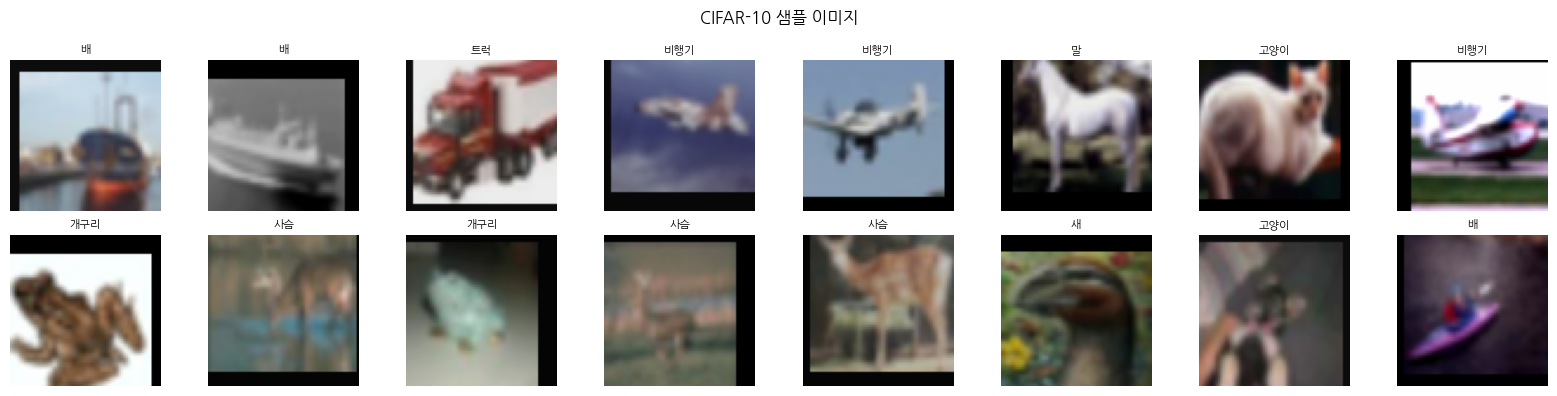

In [21]:
# ── 샘플 시각화 ──────────────────────────────────────────────────
imgs, lbs = next(iter(cifar_train_loader))
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.ravel()):
    img = imgs[i].permute(1,2,0).numpy()
    img = img * [0.2470,0.2435,0.2616] + [0.4914,0.4822,0.4465]  # 역정규화
    ax.imshow(np.clip(img, 0, 1)); ax.axis('off')
    ax.set_title(CIFAR_CLASSES[lbs[i].item()], fontsize=8)
plt.suptitle('CIFAR-10 샘플 이미지', fontsize=12)
plt.tight_layout(); plt.show()

## 2-2. ResNet18 전이학습 모델 정의

In [22]:
# ── weights : ImageNet으로 미리 학습된 가중치 사용 ──────────────
model_cifar = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Step 1 : 전체 파라미터 동결 (학습하지 않겠다는 선언)
for p in model_cifar.parameters():
    p.requires_grad = False

# Step 2 : layer4만 재학습 허용 (고수준 특징 미세조정)
for p in model_cifar.layer4.parameters():
    p.requires_grad = True

# Step 3 : 출력 레이어 교체 (ImageNet 1000클래스 → CIFAR-10 10클래스)
model_cifar.fc = nn.Linear(model_cifar.fc.in_features, 10)
# 새로 만든 fc는 requires_grad=True가 기본값

model_cifar = model_cifar.to(device)

# ── 학습 가능한 파라미터 비율 확인 ─────────────────────────────
trainable = sum(p.numel() for p in model_cifar.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model_cifar.parameters())
print(f"학습 파라미터: {trainable:,} / 전체: {total:,}  ({100*trainable/total:.1f}% 만 재학습)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


학습 파라미터: 8,398,858 / 전체: 11,181,642  (75.1% 만 재학습)


### Residual 블록 직접 확인하기

`layer1`의 첫 번째 블록을 꺼내서, 세션에서 배운 $F(x) + x$ 구조를 직접 계산해 봅시다. 블록의 실제 출력과 같으면 `True`가 나옵니다.

In [23]:
block = model_cifar.layer1[0]     # layer1의 첫 번째 Residual 블록
print(block)

block.eval()                      # 학습 함수에서 model.train()을 호출하므로 이후 학습에는 영향이 없습니다
x = torch.rand(1, 64, 16, 16).to(device)
with torch.no_grad():
    # F(x) : 블록 안의 합성곱 부분을 통과한 결과
    f_x = block.bn2(block.conv2(block.relu(block.bn1(block.conv1(x)))))
    # skip connection : F(x)에 입력을 그대로 더합니다
    out = block.relu(f_x + x)
    print("블록의 실제 출력과 같은가요?", torch.allclose(out, block(x)))

BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)
블록의 실제 출력과 같은가요? True


## 2-3. 학습 함수 (다중 분류용)

PART 1과 거의 동일하지만, 예측 방식이 다릅니다:
- 이진 분류: `torch.sigmoid(out) >= 0.5`
- **다중 분류: `out.argmax(dim=1)`** → 가장 큰 로짓 값의 인덱스가 예측 클래스

In [24]:
def train_multi(model, criterion, optimizer, loader):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        out  = model(images)
        loss = criterion(out, labels)                # CrossEntropyLoss는 argmax 불필요
        loss.backward(); optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (out.argmax(dim=1) == labels).sum().item()  # 가장 큰 값의 인덱스
        n += len(labels)
    return total_loss / n, correct / n

@torch.no_grad()
def eval_multi(model, criterion, loader):
    model.eval()
    total_loss, correct, n = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        out  = model(images)
        loss = criterion(out, labels)
        total_loss += loss.item() * len(labels)
        correct += (out.argmax(dim=1) == labels).sum().item()
        n += len(labels)
    return total_loss / n, correct / n

## 2-4. 모델 학습

`StepLR` 스케줄러: 5 에폭마다 학습률을 절반으로 줄입니다.
학습 초반에는 큰 학습률로 빠르게 이동하고, 후반엔 작은 학습률로 섬세하게 수렴합니다.

In [25]:
# 11분 정도 걸려요!!!!
criterion_cifar = nn.CrossEntropyLoss()
# filter: requires_grad=True 인 파라미터만 전달 (동결된 파라미터 제외)
optimizer_cifar = optim.AdamW(
    filter(lambda p: p.requires_grad, model_cifar.parameters()),
    lr=1e-3, weight_decay=1e-4     # weight_decay: L2 정규화 (과적합 억제)
)
# StepLR: step_size마다 lr *= gamma
scheduler = optim.lr_scheduler.StepLR(optimizer_cifar, step_size=5, gamma=0.5)

cifar_train_losses, cifar_val_losses = [], []
cifar_train_accs,   cifar_val_accs   = [], []
best_val_cifar, patience, counter = float('inf'), 5, 0

for epoch in range(20):
    tl, ta = train_multi(model_cifar, criterion_cifar, optimizer_cifar, cifar_train_loader)
    vl, va = eval_multi (model_cifar, criterion_cifar, cifar_val_loader)
    scheduler.step()                                  # 스케줄러 업데이트
    cifar_train_losses.append(tl); cifar_val_losses.append(vl)
    cifar_train_accs.append(ta);   cifar_val_accs.append(va)
    print(f"Epoch {epoch+1:2d} | Train Loss:{tl:.4f} Acc:{ta:.4f} | Val Loss:{vl:.4f} Acc:{va:.4f} | LR:{scheduler.get_last_lr()[0]:.5f}")
    if vl < best_val_cifar:
        best_val_cifar = vl; counter = 0
        torch.save(model_cifar.state_dict(), 'cifar_best.pt')
        print(f"  ✅ Best 모델 저장!")
    else:
        counter += 1
        if counter >= patience: print("⏹️  조기 종료!"); break

print("\n학습 완료!")  ##이상하게 너무 오래걸려서 전부 돌리지 못했습니다ㅜㅜ 과제 제출후 시간 여유갖고 다시 꼭 돌려보겠습니다...

Epoch  1 | Train Loss:0.8490 Acc:0.7049 | Val Loss:0.6231 Acc:0.7873 | LR:0.00100
  ✅ Best 모델 저장!
Epoch  2 | Train Loss:0.6372 Acc:0.7781 | Val Loss:0.5399 Acc:0.8137 | LR:0.00100
  ✅ Best 모델 저장!
Epoch  3 | Train Loss:0.5732 Acc:0.7992 | Val Loss:0.5093 Acc:0.8257 | LR:0.00100
  ✅ Best 모델 저장!
Epoch  4 | Train Loss:0.5259 Acc:0.8164 | Val Loss:0.5207 Acc:0.8222 | LR:0.00100
Epoch  5 | Train Loss:0.4856 Acc:0.8292 | Val Loss:0.4862 Acc:0.8318 | LR:0.00050
  ✅ Best 모델 저장!
Epoch  6 | Train Loss:0.4125 Acc:0.8550 | Val Loss:0.4559 Acc:0.8437 | LR:0.00050
  ✅ Best 모델 저장!
Epoch  7 | Train Loss:0.3823 Acc:0.8645 | Val Loss:0.4582 Acc:0.8449 | LR:0.00050
Epoch  8 | Train Loss:0.3652 Acc:0.8695 | Val Loss:0.4540 Acc:0.8473 | LR:0.00050
  ✅ Best 모델 저장!
Epoch  9 | Train Loss:0.3443 Acc:0.8793 | Val Loss:0.4588 Acc:0.8491 | LR:0.00050
Epoch 10 | Train Loss:0.3328 Acc:0.8814 | Val Loss:0.4533 Acc:0.8508 | LR:0.00025
  ✅ Best 모델 저장!
Epoch 11 | Train Loss:0.2840 Acc:0.8986 | Val Loss:0.4375 Acc:0.8600

KeyboardInterrupt: 

## 2-5. 성능 평가 & Confusion Matrix

**Confusion Matrix** : 행 = 실제 클래스, 열 = 예측 클래스
대각선이 정답, 대각선 밖이 오분류입니다.
어떤 클래스끼리 헷갈리는지(예: 고양이 ↔ 개) 한눈에 파악할 수 있습니다.

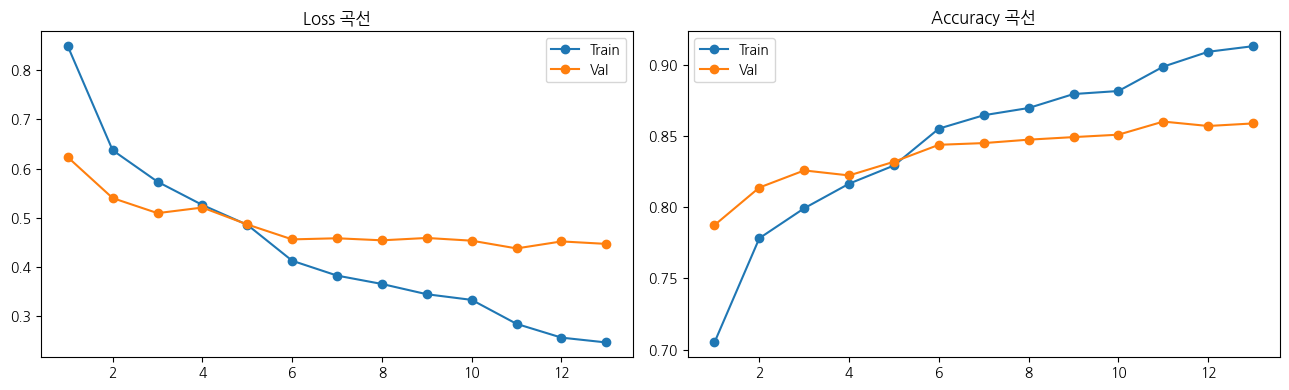

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, len(cifar_train_losses)+1)
axes[0].plot(ep, cifar_train_losses, marker='o', label='Train')
axes[0].plot(ep, cifar_val_losses,   marker='o', label='Val')
axes[0].set_title('Loss 곡선'); axes[0].legend()
axes[1].plot(ep, cifar_train_accs, marker='o', label='Train')
axes[1].plot(ep, cifar_val_accs,   marker='o', label='Val')
axes[1].set_title('Accuracy 곡선'); axes[1].legend()
plt.tight_layout(); plt.show()

🎯 테스트 Loss: 0.4329  |  테스트 Accuracy: 0.8607


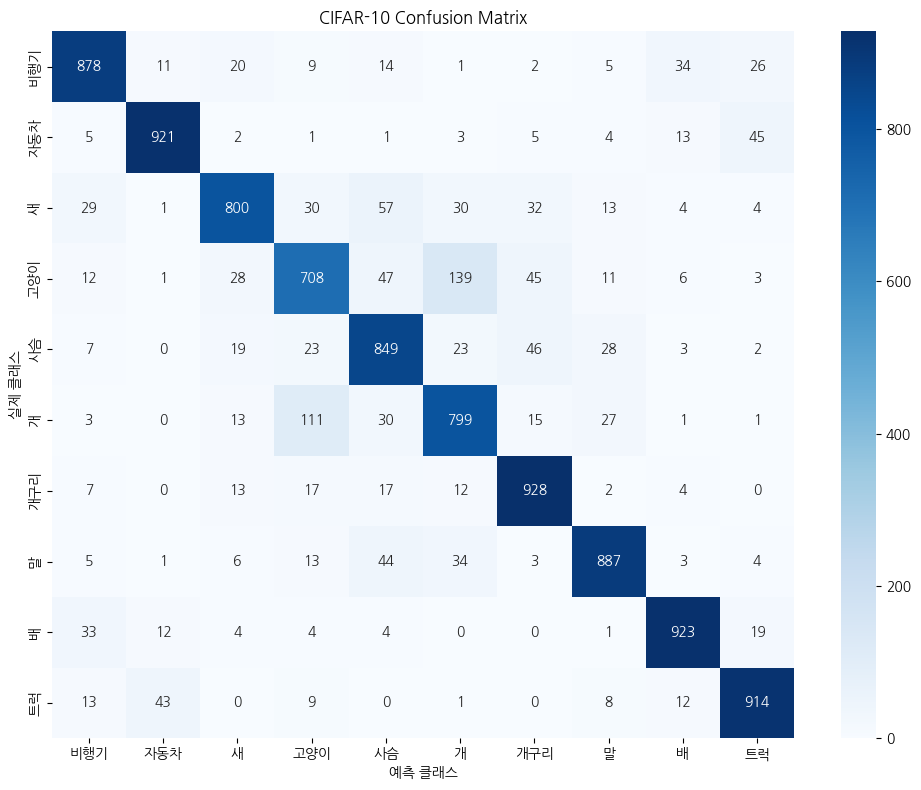

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# ── Best 모델 로드 후 테스트 평가 ────────────────────────────────
model_cifar.load_state_dict(torch.load('cifar_best.pt', map_location=device))
test_loss, test_acc = eval_multi(model_cifar, criterion_cifar, cifar_test_loader)
print(f"🎯 테스트 Loss: {test_loss:.4f}  |  테스트 Accuracy: {test_acc:.4f}")

# ── Confusion Matrix 계산 ────────────────────────────────────────
all_preds, all_labels = [], []
model_cifar.eval()
with torch.no_grad():
    for imgs, lbs in cifar_test_loader:
        preds = model_cifar(imgs.to(device)).argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(lbs.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CIFAR_CLASSES, yticklabels=CIFAR_CLASSES)
plt.title('CIFAR-10 Confusion Matrix')
plt.ylabel('실제 클래스'); plt.xlabel('예측 클래스')
plt.tight_layout(); plt.show()

---

# ✍️ 이론 확인 : 이미지 딥러닝 응용

> **객체 탐지의 두 head는 각각 무엇을 예측하나요?**
> - Classification Head: 객체가 어느 클래스인지
> - Regression Head: 객체의 위치를 연속 숫자로

> **이미지 캡셔닝에서 CNN과 RNN은 각각 어떤 역할을 하나요?**
> - CNN: 인코더
> - RNN: 디코더

> **객체 탐지와 대비해 이미지 캡셔닝의 장점은 무엇인가요?**
> - 답: 객체 간 관계와 행동, 상황까지 표현가능

# 📚 시퀀스 모델 이론 : RNN / LSTM / GRU
### 아래 질문에 답을 채워주세요!

## 1. 순환 신경망(RNN) 기초

시퀀스 데이터는 '순서'가 중요한 데이터입니다.
RNN(Recurrent Neural Network)은 이 순서를 기억하기 위해 '상태(state)'를 가지는 신경망입니다.

> **시퀀스(순차) 데이터의 큰 특징 두 가지는?**
> - 답1: 순서 중요
> - 답2: 시간적 의존성 존재

이러한 특징들로 인해 기존의 머신러닝 기법으로 시계열 데이터를 다루는 것은 한계가 있습니다.
과거의 정보를 기억하고, 순서의 의미를 학습할 수 있어 시퀀스 데이터 처리에 특화된 신경망이 **RNN**입니다!

> **RNN이 사용하는 세 가지 가중치는?**
> - 답1: 입력
> - 답2: 순환
> - 답3: 출력 가중치

**RNN의 핵심 원리는?? : 이거 지우고 적어주세요**

파라미터를 공유해서 지금까지 읽은 내용을 기억에 담아 다음으로 넘김..

---

### 기본 RNN의 세 가지 구조적 한계점

| 한계점 | 설명 |
|:---:|:---|
| 기울기 소실 | 시퀀스 뒤쪽의 오차가 앞쪽까지 제대로 전달되지 않아 먼 과거의 정보를 학습하지 못하는 현상 → 기울기가 0으로 수렴 |
| 기울기 폭주 | 시퀀스 뒤쪽의 오차가 역전파 과정에서 비정상적으로 커지는 문제 → 기울기가 무한으로 발산 |
| 느린 훈련 시간 | $t$ 시점의 은닉 상태($h_t$)를 계산하려면 $(t-1)$ 시점의 은닉 상태($h_{t-1}$)가 먼저 계산되어야 함 → 이 의존성 때문에 전체 시퀀스를 한 번에 병렬 처리 불가능 |

> 이 세 가지 한계점으로 인해 RNN은 '장기 기억력 문제'를 갖게 됩니다.

**→ 중요한 정보는 오래 기억하고, 불필요한 정보는 잊는 '똑똑한' 모델이 필요하게 되겠죠!**

---

## 2. LSTM (Long Short-Term Memory)

LSTM의 핵심 아이디어는 셀 상태(Cell State)를 따로 두는 것입니다.
LSTM은 3개의 주요 게이트를 통해 셀 상태(기억)를 관리합니다.

### 🗑️ Forget Gate (잊기 게이트)

- **역할** : 과거의 정보($C_{t-1}$) 중에서 얼마나 잊어버릴지 결정합니다.
- **동작** : 이전 시점의 출력($h_{t-1}$)과 현재 시점의 입력($x_t$)을 받아 0에서 1 사이의 값을 출력합니다. (1이면 완전히 기억, 0이면 완전히 잊음)

> 예: 문장에서 주어가 바뀌면, 이전 주어에 대한 정보를 잊도록(0에 가깝게) 신호를 보냅니다.

### 🔼 Input Gate (입력 게이트)

- **역할** : 현재 시점의 정보($x_t$) 중에서 얼마나 셀 상태에 저장할지 결정합니다.
- **동작** :
  1. 어떤 정보를 추가할지 후보($\tilde{C}_t$)를 만듭니다. (tanh 사용)
  2. 그 후보 정보를 얼마나(비율로) 추가할지 결정합니다. (sigmoid 사용)

> 예: 새로운 주어가 등장하면, 이 정보를 셀 상태에 추가하도록(1에 가깝게) 신호를 보냅니다.

> **Final memory cell의 계산:**
> $C_t$ = ( Forget Gate의 출력 $\times$ $C_{t-1}$(이전 셀 상태) ) + ( Input Gate의 출력 $\times$ $\tilde{C}_t$(새로운 후보 정보) )

### 🔽 Output Gate (출력 게이트)

- **역할** : 업데이트된 셀 상태($C_t$)의 정보 중에서 무엇을 현재 시점의 출력($h_t$)으로 내보낼지 결정합니다.
- **동작** : 셀 상태의 정보가 모두 다음 시점으로 전달될 필요는 없습니다. 현재 시점의 예측에 필요한 정보만 필터링하여 출력합니다.

> LSTM은 별도의 '셀 상태'를 통해 장기 기억을 보존하고, 3개의 게이트를 통해 이 기억을 선택적으로 잊거나, 추가하거나, 출력합니다.
> 이 구조 덕분에 **기울기 소실이 완화되어** 정보가 먼 과거까지 전달될 수 있습니다.

---

## 3. GRU (Gated Recurrent Unit)

GRU는 LSTM의 '셀 상태'와 '은닉 상태'를 하나($h_t$)로 통합하고, 게이트도 2개로 줄였습니다.

### 🔄 Reset Gate (리셋 게이트)

- **역할** : 과거 정보($h_{t-1}$)를 얼마나 무시할지 결정합니다.
- **동작** : 이 게이트가 0에 가까우면, 이전 시점의 상태($h_{t-1}$)를 거의 무시하고 현재 입력($x_t$)만으로 새로운 상태를 만들 준비를 합니다.

> LSTM의 'Forget Gate'와 유사하지만, 새로운 후보를 만들 때 관여합니다.

### 🔼 Update Gate (업데이트 게이트)

- **역할** : 과거 정보와 현재 정보의 갱신 비율을 결정합니다. (LSTM의 Forget 게이트와 Input 게이트를 하나로 합친 역할)
- **동작** :
  - 이 게이트의 값($z_t$)이 1에 가까우면: 과거 정보를 많이 무시하고, 새로운 정보($\tilde{h}_t$)를 많이 반영합니다.
  - 이 게이트의 값($z_t$)이 0에 가까우면: 새로운 정보를 무시하고, 과거 정보($h_{t-1}$)를 그대로 가져옵니다.

> GRU는 구조가 더 단순하여 LSTM보다 파라미터 수가 적고 계산 속도가 빠르면서도,
> LSTM과 비슷한, 혹은 더 좋은 성능을 보여주기도 합니다.

---

> **LSTM의 셀 상태와 은닉 상태는 각각 어떤 기억을 담당하나요?**
> - 셀 상태: 셀 상태는 장기 기억을 담당한다
> - 은닉 상태: 단기 기억. 현재 시점의 출력 작업기억

> **GRU는 LSTM과 비교해 게이트가 어떻게 달라졌나요?**
> - 답: 게이트 개수가 줄어들었다. 셀 상태와 은식을 하나로 합쳤다

---

## 4. PyTorch로 구현하기

실습과 마찬가지로 PyTorch를 사용합니다. 모델은 `nn.Module` 클래스로 정의하고, 학습은 아래 다섯 줄을 반복합니다.

```python
optimizer.zero_grad()         # 1. 기울기 초기화
outputs = model(X)            # 2. 순전파
loss = criterion(outputs, y)  # 3. 손실 계산
loss.backward()               # 4. 역전파
optimizer.step()              # 5. 가중치 업데이트
```

PyTorch는 `nn.RNN`, `nn.LSTM`, `nn.GRU`처럼 순환 레이어를 제공합니다. `nn.LSTM`의 사용법만 익혀 두면 나머지도 거의 같습니다.

| 반환값 | shape (`batch_first=True`) | 의미 |
|:---:|:---:|:---|
| `output` | (배치, 타임스텝, 은닉 크기) | **모든 타임스텝**의 은닉 상태 |
| `h_n` | (층 수, 배치, 은닉 크기) | **마지막 타임스텝**의 은닉 상태 |
| `c_n` | (층 수, 배치, 은닉 크기) | **마지막 타임스텝**의 셀 상태 (LSTM만) |

> 입력과 출력의 shape을 직접 확인하면서 코드를 채워 주세요!


In [28]:
# PyTorch로 만드는 LSTM 레이어 예시
# batch_first=True로 설정하면 (batch_size, timesteps, features) 형태의 입력을 받습니다.

# 가상의 시퀀스 데이터 생성
# 예: 32개의 문장(batch_size), 각 문장은 10개의 단어(timesteps), 각 단어는 8차원의 벡터(features)
dummy_input = torch.rand(32, 10, 8)

# LSTM 레이어 생성 (은닉 크기 64)
lstm_layer = nn.LSTM(input_size=8, hidden_size=64, batch_first=True)
output, (h_n, c_n) = lstm_layer(dummy_input)

print(f"입력 크기: {dummy_input.shape}")
print(f"output 크기 (모든 타임스텝): {output.shape}")
print(f"h_n 크기 (마지막 타임스텝): {h_n.shape}")
print(f"output의 마지막 타임스텝 크기: {output[:, -1, :].shape}")

# num_layers=2: LSTM을 2층으로 쌓으면 h_n의 첫 번째 차원이 층 수가 됩니다
stacked_lstm = nn.LSTM(input_size=8, hidden_size=64, num_layers=2, batch_first=True)
output2, (h_n2, c_n2) = stacked_lstm(dummy_input)
print(f"2층 LSTM의 h_n 크기: {h_n2.shape}")

입력 크기: torch.Size([32, 10, 8])
output 크기 (모든 타임스텝): torch.Size([32, 10, 64])
h_n 크기 (마지막 타임스텝): torch.Size([1, 32, 64])
output의 마지막 타임스텝 크기: torch.Size([32, 64])
2층 LSTM의 h_n 크기: torch.Size([2, 32, 64])


---

# 📝 PART 3. LSTM 텍스트 감성 분석 (NSMC, PyTorch)

한국어 영화 리뷰 데이터인 **NSMC(네이버 영화 리뷰)** 로 리뷰의 긍정/부정을 분류합니다. 마지막에는 학습한 모델을 직접 속여 보는 챌린지도 있어요!

이번에는 텍스트를 딥러닝으로 처리하는 가장 표준적인 두 가지 기술을 배웁니다.

**1. Embedding (임베딩) 레이어**
- 왜 필요할까요?
컴퓨터는 '재', '밌' 같은 글자를 직접 이해할 수 없습니다. 모든 것을 숫자로 바꿔주어야 합니다.

- 어떻게 작동하나요?
  a. 토큰을 숫자로 매핑: 데이터에 있는 고유한 토큰 각각에 고유한 번호(인덱스)를 부여합니다.
  b. 숫자를 '벡터'로 변환: Embedding 레이어가 이 번호(인덱스)를 **Dense Vector**로 변환합니다. (예: 128차원의 숫자 배열)
  > 재 (글자) ➔ 5 (인덱스) ➔ [0.1, 0.5, -0.2, ... , 0.9] (128차원 벡터)

  c. '의미'를 학습: 이 벡터의 값은 학습 과정에서 분류에 도움이 되는 방향으로 조정됩니다.

> 즉, Embedding은 텍스트를 컴퓨터가 이해할 수 있는 숫자 벡터로 바꿔 주는 첫 단계입니다.

**왜 단어가 아니라 음절(글자) 단위일까요?**
한국어는 "재밌다", "재밌었어요", "재밌네"처럼 어미에 따라 형태가 계속 바뀝니다. 띄어쓰기로 나누면 전부 다른 단어가 되기 때문에, 이번에는 별도 설치가 필요 없는 음절 단위를 사용합니다.

<br><br>
**2. Bidirectional LSTM (양방향 LSTM)**
- 왜 그냥 LSTM이 아니라 '양방향'을 쓸까요?
RNN과 LSTM은 텍스트와 같은 시퀀스 데이터를, 앞에서부터 차례대로 읽으며 '기억'(Context)을 쌓아갑니다.

  **하지만 문장의 의미는 뒤에 나오는 말에 따라 달라질 때가 많습니다.**

  예시 1: "기대 안 했는데 재밌었다."

  "기대 안 했는데"만 보면 부정적이지만, 뒤에 "재밌었다"가 나옵니다.

  예시 2: "영상미는 훌륭한데 스토리가 최악이다."

  "훌륭한데" 때문에 긍정으로 판단하다가, 마지막 "최악이다"를 보고 부정으로 결론 내려야 합니다.

- 어떻게 작동하나요?
`nn.LSTM`에 `bidirectional=True`를 주면 LSTM을 두 방향으로 만듭니다.

  - 정방향 (Forward) LSTM: 문장을 앞 -> 뒤로 읽습니다.

  - 역방향 (Backward) LSTM: 문장을 뒤 -> 앞으로 읽습니다.

  모델은 이 두 방향의 '기억(출력)'을 모두 합쳐서 최종 결정을 내립니다.

> 그 결과, 모델은 각 글자의 앞뒤 문맥을 함께 볼 수 있습니다.

---

## 3-1. 데이터 로드 및 전처리

In [29]:
# ── NSMC 데이터셋 로드 (네이버 영화 리뷰) ───────────────────────
from collections import Counter

max_features = 3000    # 빈도 상위 3,000개 글자만 사용 (나머지는 <unk> 처리)
maxlen       = 80      # 각 리뷰를 80글자로 통일 (짧으면 패딩, 길면 자름)

base_url = "https://raw.githubusercontent.com/e9t/nsmc/master/"
# quoting=3 : 리뷰 속 큰따옴표를 그대로 읽습니다
train_df = pd.read_csv(base_url + "ratings_train.txt", sep="\t", quoting=3).dropna(subset=["document"]).drop_duplicates(subset=["document"])
val_df   = pd.read_csv(base_url + "ratings_test.txt",  sep="\t", quoting=3).dropna(subset=["document"]).drop_duplicates(subset=["document"])
val_df   = val_df[~val_df["document"].isin(train_df["document"])]   # 학습 데이터와 겹치는 리뷰는 제외

# 학습 시간을 줄이기 위해 일부만 사용합니다
train_df = train_df.sample(50000, random_state=42)
val_df   = val_df.sample(10000, random_state=42)

train_texts, y_train = train_df["document"].tolist(), train_df["label"].tolist()
val_texts,   y_val   = val_df["document"].tolist(),   val_df["label"].tolist()
print(f"훈련: {len(train_texts)}개  |  검증: {len(val_texts)}개")
print(f"첫 번째 리뷰: {train_texts[0]}")
print(f"레이블: {y_train[0]} ({'긍정' if y_train[0]==1 else '부정'})")

훈련: 50000개  |  검증: 10000개
첫 번째 리뷰: 재밌네요 ㅎㅎ
레이블: 1 (긍정)


In [30]:
# ── 글자 사전 만들기 (글자 → 정수) ──────────────────────────────
counter = Counter()
for text in train_texts:          # 데이터 누수를 막기 위해 훈련 데이터로만 사전을 만듭니다
    counter.update(text)          # 문자열을 넣으면 글자 단위로 셉니다

# 0번은 패딩, 1번은 사전에 없는 글자(<unk>)에 배정합니다
char_index = {"<pad>": 0, "<unk>": 1}
for char, _ in counter.most_common(max_features - 2):   # 빈도가 높은 순으로 글자를 가져옵니다
    char_index[char] = len(char_index)
print(f"글자 사전 크기: {len(char_index)}")

# ── 정수 인코딩 + 패딩 (Padding) ────────────────────────────────
# 리뷰마다 길이가 다름 → 배치 처리를 위해 동일한 길이로 맞춤
# 짧은 리뷰는 뒤를 0으로 채움 (post-padding), 긴 리뷰는 뒤를 자름
def encode_and_pad(text):
    tokens = [char_index.get(c, 1) for c in text][:maxlen]
    return tokens + [0] * (maxlen - len(tokens))

X_train_nsmc = torch.tensor([encode_and_pad(t) for t in train_texts], dtype=torch.long)
X_val_nsmc   = torch.tensor([encode_and_pad(t) for t in val_texts],   dtype=torch.long)
print(f"\n패딩 후 shape: {X_train_nsmc.shape}")  # (50000, 80)

nsmc_train_loader = DataLoader(torch.utils.data.TensorDataset(X_train_nsmc, torch.tensor(y_train, dtype=torch.float32)),
                               batch_size=128, shuffle=True)
nsmc_val_loader   = DataLoader(torch.utils.data.TensorDataset(X_val_nsmc, torch.tensor(y_val, dtype=torch.float32)),
                               batch_size=128, shuffle=False)

글자 사전 크기: 2337

패딩 후 shape: torch.Size([50000, 80])


## 3-2. Bidirectional LSTM 모델 구축

```
입력 → Embedding → BiLSTM 2층 → Dropout → Linear(출력 1개)
```

양방향 LSTM의 `h_n` shape은 (층 수 × 2, 배치, 은닉 크기)입니다.
- `h_n[-2]` : 마지막 층의 **정방향** 은닉 상태
- `h_n[-1]` : 마지막 층의 **역방향** 은닉 상태

두 벡터를 이어 붙이므로 `Linear`의 입력 크기는 `hidden_size * 2`가 됩니다.

> `pack_padded_sequence`는 LSTM이 패딩을 건너뛰고 실제 글자까지만 읽게 해 줍니다. NSMC는 리뷰가 짧아 패딩이 많기 때문에 사용합니다.

In [32]:
from torch.nn.utils.rnn import pack_padded_sequence

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_size=64, num_layers=2):
        super().__init__()
        # Embedding : (배치, 시퀀스길이) → (배치, 시퀀스길이, 128)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # 2층 BiLSTM
        self.lstm = nn.LSTM(embed_dim, hidden_size, num_layers=num_layers,
                            batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)              # 과적합 방지
        self.fc = nn.Linear(hidden_size * 2, 1)   # 이진 분류 → 출력 1개

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()   # 패딩을 뺀 실제 길이
        packed = pack_padded_sequence(self.embedding(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        h = torch.cat([h_n[-2], h_n[-1]], dim=1)    # 정방향 + 역방향
        return self.fc(self.dropout(h)).squeeze(1)  # Sigmoid는 손실 함수에 포함되어 있습니다

model_nsmc = BiLSTMClassifier(len(char_index)).to(device)
print(model_nsmc)

BiLSTMClassifier(
  (embedding): Embedding(2337, 128, padding_idx=0)
  (lstm): LSTM(128, 64, num_layers=2, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


## 3-3. 학습 및 결과

In [34]:
criterion_nsmc = nn.BCEWithLogitsLoss()   # 이진 분류 손실 (Sigmoid 포함, Part 1과 동일)
optimizer_nsmc = optim.Adam(model_nsmc.parameters())

nsmc_history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

for epoch in range(5):
    # ── 학습 ──
    model_nsmc.train()
    total_loss, correct, n = 0, 0, 0
    for texts, labels in nsmc_train_loader:
        texts, labels = texts.to(device), labels.to(device)
        optimizer_nsmc.zero_grad()
        outputs = model_nsmc(texts)
        loss = criterion_nsmc(outputs, labels)
        loss.backward()
        optimizer_nsmc.step()
        total_loss += loss.item() * len(labels)
        correct += ((outputs > 0).float() == labels).sum().item()  # 로짓 > 0 은 확률 > 0.5와 같습니다
        n += len(labels)
    nsmc_history['loss'].append(total_loss / n)
    nsmc_history['accuracy'].append(correct / n)

    # ── 검증 ──
    model_nsmc.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.no_grad():
        for texts, labels in nsmc_val_loader:
            texts, labels = texts.to(device), labels.to(device)
            outputs = model_nsmc(texts)
            total_loss += criterion_nsmc(outputs, labels).item() * len(labels)
            correct += ((outputs > 0).float() == labels).sum().item()
            n += len(labels)
    nsmc_history['val_loss'].append(total_loss / n)
    nsmc_history['val_accuracy'].append(correct / n)

    print(f"Epoch {epoch+1}/5 | Train Loss:{nsmc_history['loss'][-1]:.4f} Acc:{nsmc_history['accuracy'][-1]:.4f}"
          f" | Val Loss:{nsmc_history['val_loss'][-1]:.4f} Acc:{nsmc_history['val_accuracy'][-1]:.4f}")

Epoch 1/5 | Train Loss:0.5083 Acc:0.7427 | Val Loss:0.4424 Acc:0.7902
Epoch 2/5 | Train Loss:0.3969 Acc:0.8178 | Val Loss:0.4105 Acc:0.8087
Epoch 3/5 | Train Loss:0.3497 Acc:0.8449 | Val Loss:0.3907 Acc:0.8198
Epoch 4/5 | Train Loss:0.3123 Acc:0.8645 | Val Loss:0.3733 Acc:0.8316
Epoch 5/5 | Train Loss:0.2797 Acc:0.8798 | Val Loss:0.3859 Acc:0.8329


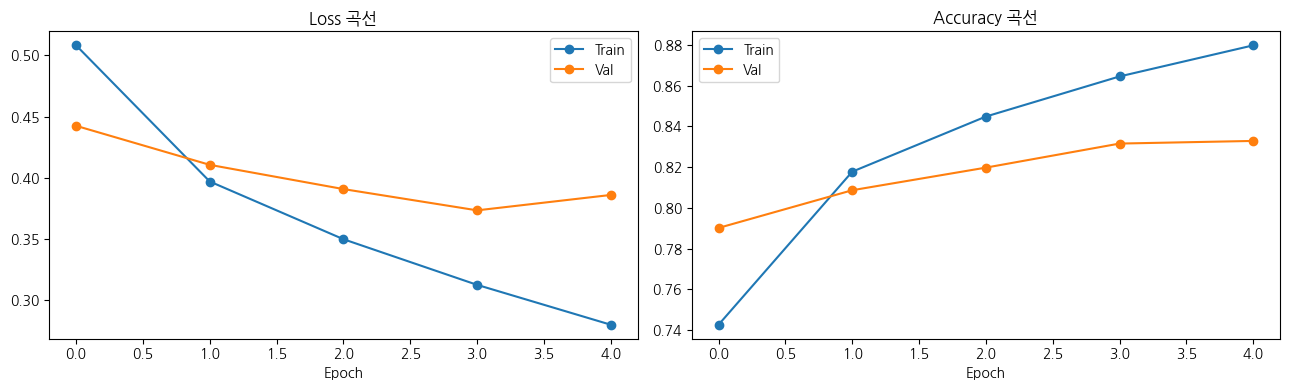

최종 Val Accuracy: 0.8329


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(nsmc_history['loss'],     marker='o', label='Train')
axes[0].plot(nsmc_history['val_loss'], marker='o', label='Val')
axes[0].set_title('Loss 곡선'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(nsmc_history['accuracy'],     marker='o', label='Train')
axes[1].plot(nsmc_history['val_accuracy'], marker='o', label='Val')
axes[1].set_title('Accuracy 곡선'); axes[1].set_xlabel('Epoch'); axes[1].legend()

plt.tight_layout(); plt.show()
print(f"최종 Val Accuracy: {nsmc_history['val_accuracy'][-1]:.4f}")

## 3-4. 직접 리뷰 입력해서 예측해보기

학습된 모델로 새로운 문장을 분류해봅니다.
내부적으로는 글자 → 정수 인코딩 → 패딩 → 모델 예측 순서로 진행됩니다.

In [36]:
def review_score(text):
    # 학습 데이터와 똑같이 정수 인코딩 + 패딩을 적용합니다
    padded = torch.tensor([encode_and_pad(text)], dtype=torch.long).to(device)
    model_nsmc.eval()
    with torch.no_grad():
        # 모델 출력은 로짓이므로 sigmoid로 0~1 사이 확률값으로 바꿉니다
        return torch.sigmoid(model_nsmc(padded)).item()

def predict_review(text):
    score = review_score(text)
    print(f"입력 : {text}")
    print(f"점수 : {score:.4f}  →  {'긍정 😊' if score > 0.5 else '부정 😞'}\n")

# 다양한 리뷰 테스트 해보세요!!! (예시 말구... 바꿔서 해보세요!!!! 꼭!!)
# 긍정 리뷰 테스트
predict_review("정말 감동적이었어요. 배우들 연기도 최고입니다!")
# 부정 리뷰 테스트
predict_review("시간 아깝다. 스토리도 지루하고 연기도 별로.")
# 중립 리뷰 테스트
predict_review("그냥 그랬어요. 최고는 아니지만 최악도 아니에요.")

입력 : 정말 감동적이었어요. 배우들 연기도 최고입니다!
점수 : 0.9979  →  긍정 😊

입력 : 시간 아깝다. 스토리도 지루하고 연기도 별로.
점수 : 0.0006  →  부정 😞

입력 : 그냥 그랬어요. 최고는 아니지만 최악도 아니에요.
점수 : 0.0124  →  부정 😞



## 3-5. 🎯 참여형 과제: 모델 속이기 챌린지

정답이 없는 파트입니다! 방금 학습한 모델이 **틀리도록** 리뷰를 직접 써 보세요. 제출한 문장은 세션에서 함께 구경합니다 👀

### 미션
1. **긍정 속이기** : 사람이 읽으면 긍정인데, 모델은 부정이라고 답하는 문장을 찾으세요.
2. **부정 속이기** : 사람이 읽으면 부정인데, 모델은 긍정이라고 답하는 문장을 찾으세요.
3. **원인 추측하기** : 글자나 단어를 조금씩 바꿔 가며 점수 변화를 보고, 모델이 왜 속았는지 가설을 세워 보세요.

### 규칙
- 실제 영화 리뷰처럼 자연스러운 **한국어 문장**으로, **30자 이내**로 써 주세요.
- 줄임말이나 "ㅋㅋ" 같은 표현은 사용해도 됩니다!
- 의미 없는 글자를 나열하거나 일부러 오타를 내면 안 됩니다.

> 💡 반어법, 돌려 말하기, 앞뒤가 뒤집히는 문장 등을 시도해 보세요!

In [37]:
# ✏️ 큰따옴표 안의 내용을 지우고 직접 쓴 문장을 넣어 주세요. 여러 문장을 시도해도 좋아요!
fool_positive = [
    "죽여준다",
]
fool_negative = [
    "참 잘 하는 짓이다!",
]

print("── 긍정 속이기 (점수가 0.5보다 작으면 성공!) ──")
for text in fool_positive:
    score = review_score(text)
    print(f"{score:.4f}  {'🎉 성공' if score < 0.5 else '실패'}  {text}")

print("\n── 부정 속이기 (점수가 0.5보다 크면 성공!) ──")
for text in fool_negative:
    score = review_score(text)
    print(f"{score:.4f}  {'🎉 성공' if score > 0.5 else '실패'}  {text}")

── 긍정 속이기 (점수가 0.5보다 작으면 성공!) ──
0.4596  🎉 성공  죽여준다

── 부정 속이기 (점수가 0.5보다 크면 성공!) ──
0.5960  🎉 성공  참 잘 하는 짓이다!


In [38]:
# ✏️ 속인 문장을 조금씩 바꿔 가며 점수 변화를 확인해 보세요.
experiments = [
    "죽여준다",
    "죽이지 않냐?",
]

for text in experiments:
    print(f"{review_score(text):.4f}  {text}")

0.4596  죽여준다
0.0661  죽이지 않냐?


### 📮 제출 양식 (이 셀을 수정해 주세요)

| 미션 | 문장 | 모델 점수 |
|:---:|:---|:---:|
| 긍정 속이기 |죽여준다 | |
| 부정 속이기 |참 잘 하는 짓이다! | |

**모델이 왜 속았을까요? (내 가설)** 죽이다라는 글자 문맥이 부정적인 맥락에서 많아 사용되닉 때문:

**문장을 바꿔 보면서 알게 된 점** :문장이 짧으면 더 쉽게 속는 거 같다

---

# 🌡️ PART 4. LSTM 시계열 기온 예측 (예나 기후, PyTorch)

독일 예나(Jena)의 기후 데이터로 **6시간 뒤의 기온**을 예측합니다.
과거 5일치(120시간) 13개 기상 피처 → 미래 기온 (**다변량 회귀 예측**)

## 🔑 핵심 개념

### 시계열 데이터 처리 주의사항

> ⚠️ **랜덤 분할 절대 금지!**

시계열 데이터를 랜덤으로 섞으면 **미래 데이터가 학습에 사용**되는 데이터 누수(Data Leakage)가 발생합니다.
반드시 **시간 순서대로 분할**해야 합니다.

```
전체 데이터 (시간 순서)
├── 0% ~ 70%  : 훈련 셋
├── 70% ~ 90% : 검증 셋
└── 90% ~ 100%: 테스트 셋
```

### 슬라이딩 윈도우 방식

```
[t=0 ~ t=119] → 예측: t=125
[t=1 ~ t=120] → 예측: t=126
[t=2 ~ t=121] → 예측: t=127
...
```

하나의 데이터로 여러 학습 샘플을 만들 수 있습니다.

### 정규화 주의사항
검증/테스트 셋 정규화에도 **훈련 셋의 평균/표준편차**를 사용해야 합니다.
그렇지 않으면 미래 통계값이 학습에 영향을 미쳐 데이터 누수가 됩니다.

---

## 4-1. 데이터 로드

> 📁 `jena_climate_2009_2016.csv` 파일이 필요합니다!!! (git, 노션에 다 있습니다)

In [42]:
file_path = "/content/sample_data/jena_climate_2009_2016.csv"

df = pd.read_csv(file_path)
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')

df = pd.read_csv(file_path)
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df.set_index('Date Time', inplace=True)

# 원래 10분 간격 → 1시간 간격으로 다운샘플링 (6배 간격으로 추출)
df = df[::6]

# 풍속 컬럼에는 결측을 뜻하는 -9999가 섞여 있어서 0으로 바꿉니다 (그대로 두면 정규화 후 값이 수천까지 튑니다)
df = df.replace(-9999.0, 0.0)

print(f"데이터 형태: {df.shape}")
print(f"기간: {df.index[0]} ~ {df.index[-1]}")
print("\n컬럼 목록:")
print(list(df.columns))
df.head()

데이터 형태: (15318, 14)
기간: 2009-01-01 00:10:00 ~ 2010-09-30 05:30:00

컬럼 목록:
['p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
Date Time,,,,,,,,,,,,,,
2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
2009-01-01 01:10:00,996.50,-7.62,265.81,-8.30,94.8,3.44,3.26,0.18,2.04,3.27,1305.68,0.18,0.63,166.5
2009-01-01 02:10:00,996.63,-8.85,264.57,-9.70,93.5,3.12,2.92,0.20,1.82,2.93,1312.11,0.16,0.50,158.3
2009-01-01 03:10:00,996.87,-8.84,264.56,-9.69,93.5,3.13,2.92,0.20,1.83,2.93,1312.37,0.07,0.25,129.3
2009-01-01 04:10:00,997.05,-9.23,264.15,-10.25,92.2,3.03,2.79,0.24,1.74,2.80,1314.62,0.10,0.38,203.9


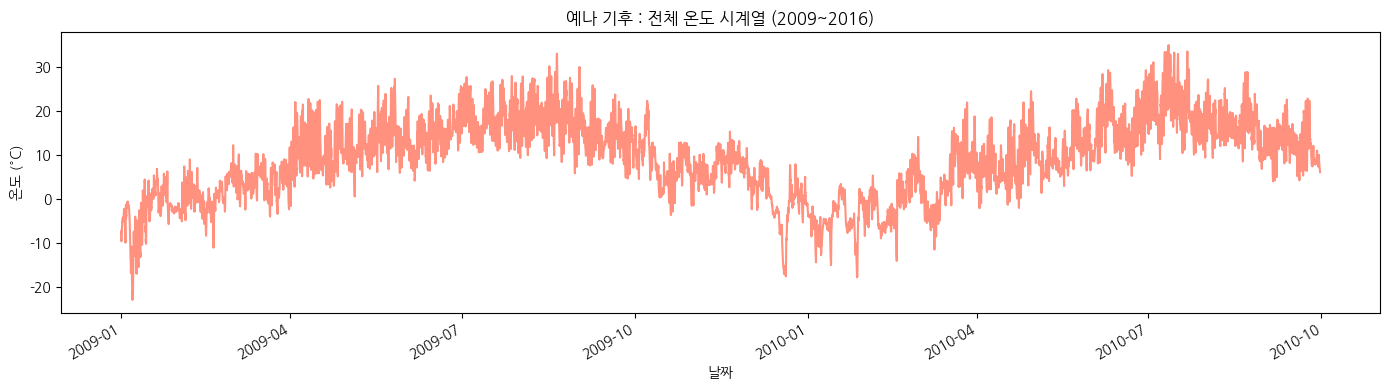

온도 범위: -23.0°C ~ 34.9°C


In [43]:
# ── 전체 온도 시계열 시각화 ─────────────────────────────────────
df['T (degC)'].plot(figsize=(14, 4), color='tomato', alpha=0.7)
plt.title('예나 기후 : 전체 온도 시계열 (2009~2016)')
plt.ylabel('온도 (°C)'); plt.xlabel('날짜')
plt.tight_layout(); plt.show()
print(f"온도 범위: {df['T (degC)'].min():.1f}°C ~ {df['T (degC)'].max():.1f}°C")

## 4-2. 데이터 분리 및 정규화

In [44]:
target_col = 'T (degC)'
X = df.drop(columns=[target_col])   # 피처 (13개)
y = df[target_col].values           # 타깃 (예측할 온도)

n = len(df)
train_end = int(n * 0.7)
val_end   = int(n * 0.9)

# ── 반드시 훈련 셋 통계로만 정규화! ─────────────────────────────
train_mean = X.iloc[:train_end].mean()
train_std  = X.iloc[:train_end].std()
X_norm     = (X - train_mean) / train_std  # Z-score 정규화

X_data = X_norm.values
X_train, y_train = X_data[:train_end],       y[:train_end]
X_val,   y_val   = X_data[train_end:val_end], y[train_end:val_end]
X_test,  y_test  = X_data[val_end:],          y[val_end:]

print(f"Train : {X_train.shape}  |  y_train: {y_train.shape}")
print(f"Val   : {X_val.shape}    |  y_val:   {y_val.shape}")
print(f"Test  : {X_test.shape}   |  y_test:  {y_test.shape}")

Train : (10722, 13)  |  y_train: (10722,)
Val   : (3064, 13)    |  y_val:   (3064,)
Test  : (1532, 13)   |  y_test:  (1532,)


## 4-3. 슬라이딩 윈도우 데이터셋 생성

`Dataset`을 직접 만들어 슬라이딩 윈도우를 구현합니다.

- `sequence_length=120` : 120시간(5일)을 입력으로 사용
- `delay=6` : 입력의 **마지막 시점**에서 6시간 뒤의 온도를 예측

> `i`번째 샘플의 입력은 `X[i : i+120]`이고, 정답은 `y[i + 120 + 6 - 1]`입니다.
> 예를 들어 `i=0`이면 t=0~119를 보고 **t=125**의 온도를 예측합니다.

In [45]:
sequence_length = 120   # 과거 120시간 (5일)
delay           = 6     # 6시간 뒤 예측
batch_size      = 256

class JenaDataset(Dataset):
    def __init__(self, X, y, seq_len, delay):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.seq_len = seq_len
        self.delay   = delay

    def __len__(self):
        return len(self.X) - self.seq_len - self.delay + 1  # 만들 수 있는 윈도우 개수

    def __getitem__(self, i):
        x = self.X[i : i + self.seq_len]                   # 입력: seq_len개 연속 데이터
        target = self.y[i + self.seq_len + self.delay - 1]  # 정답: 입력 끝 시점에서 delay 뒤의 온도
        return x, target

train_loader_jena = DataLoader(JenaDataset(X_train, y_train, sequence_length, delay), batch_size=batch_size, shuffle=True)
val_loader_jena   = DataLoader(JenaDataset(X_val,   y_val,   sequence_length, delay), batch_size=batch_size)
test_loader_jena  = DataLoader(JenaDataset(X_test,  y_test,  sequence_length, delay), batch_size=batch_size)

x_batch, y_batch = next(iter(train_loader_jena))
print(f"입력 shape: {x_batch.shape}  ← (배치, 120타임스텝, 13피처)")
print(f"타깃 shape: {y_batch.shape}  ← (배치,)")

입력 shape: torch.Size([256, 120, 13])  ← (배치, 120타임스텝, 13피처)
타깃 shape: torch.Size([256])  ← (배치,)


## 4-4. LSTM 모델 구축 및 학습


회귀 문제이므로 출력 레이어에 **활성화 함수 없음**, 손실 함수는 **MSE** (평균 제곱 오차)를 사용합니다.
평가 지표로 **MAE** (평균 절대 오차, 단위: °C)를 함께 확인합니다.

이제 (120, 13) 형태의 입력을 받아 (1,) 형태의 출력을 내보내는 모델을 만듭니다.
여기서는 EarlyStopping도 직접 구현해 볼게요.

In [46]:
# ── 2층 Stacked LSTM ─────────────────────────────────────────────
class StackedLSTM(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        # 1층: output(모든 타임스텝)을 다음 LSTM에 전달
        self.lstm1 = nn.LSTM(input_size, 64, batch_first=True)
        # 2층: 마지막 hidden state만 사용
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        # Dropout 레이어: 과적합 방지
        # 0.2는 Dropout rate로, 학습 시 랜덤하게 전체 뉴런의 20%를 꺼서 과적합을 방지합니다.
        self.dropout = nn.Dropout(0.2)
        # 회귀 출력 : 활성화 함수 없음 (임의 실수값 출력)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.lstm1(x)
        _, (h_n, _) = self.lstm2(output)
        return self.fc(self.dropout(h_n[-1])).squeeze(1)

model_jena = StackedLSTM(X_train.shape[-1]).to(device)
print(model_jena)

# 손실(Loss): Mean Squared Error (평균 제곱 오차)
criterion_jena = nn.MSELoss()
optimizer_jena = optim.Adam(model_jena.parameters())


@torch.no_grad()
def evaluate_jena(model, loader):
    # MSE와 MAE(평균 절대 오차, 해석이 쉬움: °C 단위), 예측값을 반환합니다
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).cpu())
        targets.append(y)
    preds, targets = torch.cat(preds), torch.cat(targets)
    mse = ((preds - targets) ** 2).mean().item()
    mae = (preds - targets).abs().mean().item()
    return mse, mae, preds.numpy(), targets.numpy()

StackedLSTM(
  (lstm1): LSTM(13, 64, batch_first=True)
  (lstm2): LSTM(64, 32, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


In [47]:
# EarlyStopping: val_loss가 patience번 연속으로 개선되지 않으면, 100번을 다 채우기 전에 훈련을 "조기 종료" 하는 과적합 방지 기법입니다.
num_epochs = 100
patience   = 10
best_val_loss, early_stop_counter, best_state = float('inf'), 0, None
history_jena = {'loss': [], 'val_loss': [], 'mae': [], 'val_mae': []}

for epoch in range(num_epochs):
    model_jena.train()
    total_loss, total_mae, n = 0, 0, 0
    for x, y in train_loader_jena:
        x, y = x.to(device), y.to(device)
        optimizer_jena.zero_grad()
        outputs = model_jena(x)
        loss = criterion_jena(outputs, y)
        loss.backward()
        optimizer_jena.step()
        total_loss += loss.item() * len(y)
        total_mae  += (outputs - y).abs().sum().item()
        n += len(y)

    val_loss, val_mae, _, _ = evaluate_jena(model_jena, val_loader_jena)
    history_jena['loss'].append(total_loss / n);  history_jena['mae'].append(total_mae / n)
    history_jena['val_loss'].append(val_loss);    history_jena['val_mae'].append(val_mae)
    print(f"Epoch {epoch+1}/{num_epochs} | loss:{total_loss/n:.4f} mae:{total_mae/n:.4f} | val_loss:{val_loss:.4f} val_mae:{val_mae:.4f}")

    if val_loss < best_val_loss:                 # 검증 손실이 개선되면 카운터를 초기화하고 가중치를 저장
        best_val_loss, early_stop_counter = val_loss, 0
        best_state = copy.deepcopy(model_jena.state_dict())
    else:
        early_stop_counter += 1
        if early_stop_counter >= patience:
            print("⏹️  조기 종료!")
            break

model_jena.load_state_dict(best_state)            # 학습 종료 후 Best 가중치로 복원

Epoch 1/100 | loss:111.6491 mae:8.4801 | val_loss:171.4510 val_mae:11.0843
Epoch 2/100 | loss:75.0658 mae:6.7118 | val_loss:130.3755 val_mae:9.2649
Epoch 3/100 | loss:57.6084 mae:5.7224 | val_loss:105.9868 val_mae:8.1192
Epoch 4/100 | loss:45.2899 mae:4.9491 | val_loss:88.9436 val_mae:7.2943
Epoch 5/100 | loss:36.8739 mae:4.3881 | val_loss:76.0049 val_mae:6.6628
Epoch 6/100 | loss:30.8675 mae:3.9999 | val_loss:66.9517 val_mae:6.2714
Epoch 7/100 | loss:26.3083 mae:3.6735 | val_loss:58.8135 val_mae:5.7201
Epoch 8/100 | loss:23.2326 mae:3.4775 | val_loss:52.0915 val_mae:5.3932
Epoch 9/100 | loss:20.3288 mae:3.2246 | val_loss:46.4893 val_mae:5.0055
Epoch 10/100 | loss:17.9547 mae:3.0223 | val_loss:41.1874 val_mae:4.6264
Epoch 11/100 | loss:15.5578 mae:2.7922 | val_loss:37.0577 val_mae:4.3482
Epoch 12/100 | loss:13.8194 mae:2.6163 | val_loss:33.8638 val_mae:4.1450
Epoch 13/100 | loss:12.6409 mae:2.5055 | val_loss:31.3162 val_mae:3.9955
Epoch 14/100 | loss:11.2059 mae:2.3559 | val_loss:28.33

<All keys matched successfully>

## 4-5. 결과 시각화

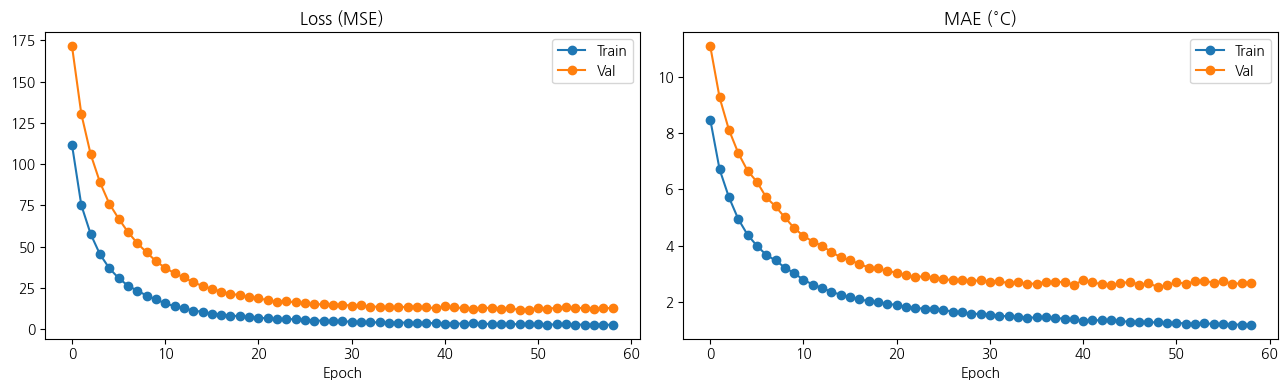

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_jena['loss'],     marker='o', label='Train')
axes[0].plot(history_jena['val_loss'], marker='o', label='Val')
axes[0].set_title('Loss (MSE)'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(history_jena['mae'],     marker='o', label='Train')
axes[1].plot(history_jena['val_mae'], marker='o', label='Val')
axes[1].set_title('MAE (°C)'); axes[1].set_xlabel('Epoch'); axes[1].legend()

plt.tight_layout(); plt.show()

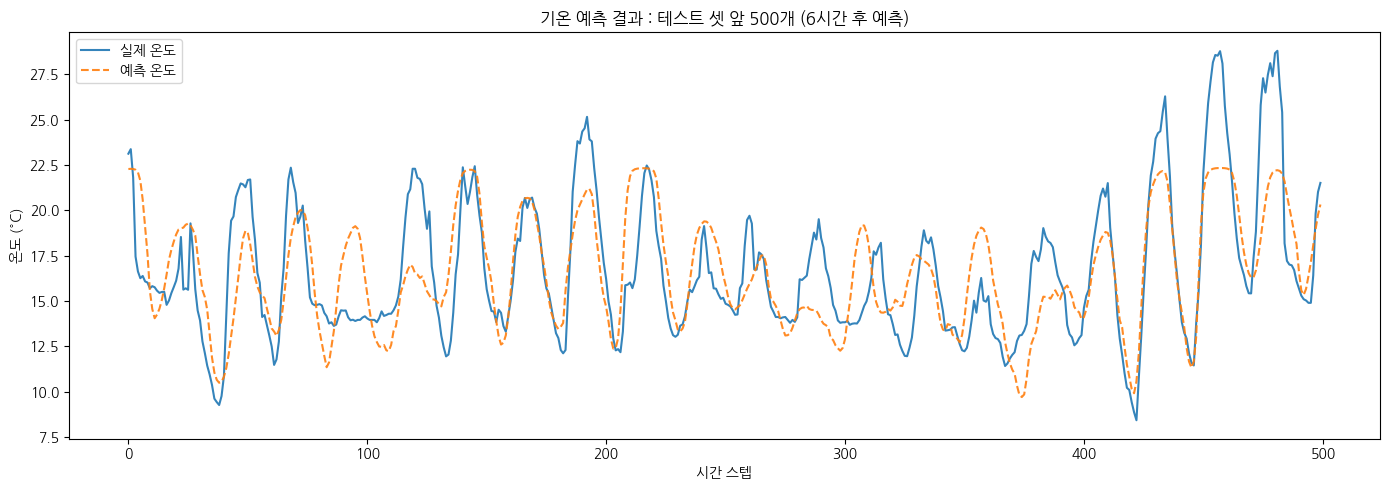

🎯 테스트 MSE: 6.3599  |  테스트 MAE: 1.9503 °C
   → 평균 1.95°C 오차로 예측!


In [49]:
# ── 테스트 셋 예측 & 시각화 ─────────────────────────────────────
test_loss, test_mae, y_pred, y_actual = evaluate_jena(model_jena, test_loader_jena)

plt.figure(figsize=(14, 5))
plt.plot(y_actual[:500], label='실제 온도', alpha=0.9)
plt.plot(y_pred[:500],   label='예측 온도', linestyle='--', alpha=0.9)
plt.title('기온 예측 결과 : 테스트 셋 앞 500개 (6시간 후 예측)')
plt.ylabel('온도 (°C)'); plt.xlabel('시간 스텝')
plt.legend(); plt.tight_layout(); plt.show()

print(f"🎯 테스트 MSE: {test_loss:.4f}  |  테스트 MAE: {test_mae:.4f} °C")
print(f"   → 평균 {test_mae:.2f}°C 오차로 예측!")

---

# ✍️ 이론 확인 : Seq2Seq

> **Seq2Seq에서 병목 현상이 발생하는 이유는? 입력이 길어지면 어떻게 되나요?**
> - 이유: 컨텍스트 벡터 하나로 압축해서
> - 입력이 길어지면: 앞정보가 희미해진다

---

# 🔤 PART 5. Character-Level Seq2Seq : 소문자 → 대문자 변환

**Seq2Seq** (Sequence-to-Sequence) 는 입력 시퀀스를 받아 다른 시퀀스를 출력하는 구조입니다.
기계 번역, 텍스트 요약, 챗봇 등에 활용됩니다.

## 🔑 핵심 구조

```
"hello"
   ↓
[인코더 LSTM] → hidden state (h, c) = "컨텍스트 벡터"
                                ↓
                     [디코더 LSTM] → "H"
                                   → "E"
                                   → "L"
                                   → "L"
                                   → "O"
```

### 인코더 (Encoder)
입력 시퀀스를 **왼쪽→오른쪽으로 읽으며** 마지막 `(h, c)` = **컨텍스트 벡터**에 전체 문맥을 압축합니다.

### 디코더 (Decoder)
컨텍스트 벡터를 초기 상태로 받아, **한 글자씩 순차적으로 생성**합니다.
`<start>` 토큰(`	`)을 첫 입력으로 주면, 이후 `<end>` 토큰(`
`)이 나올 때까지 생성합니다.

### Teacher Forcing 💡
학습 시 디코더의 각 스텝에 **이전 예측값 대신 실제 정답**을 입력으로 넣습니다.
- 왜? 초기 예측이 틀리면 오류가 쌓여 학습이 불안정해질 수 있기 때문
- `decoder_input_data`  : `	` + 정답 (시작 토큰 붙인 정답)
- `decoder_target_data` : 정답 + `
` (끝 토큰 붙인 정답)

### 학습 vs 추론

학습과 추론은 **같은 인코더와 디코더**를 쓰고, 디코더에 넣는 입력만 다릅니다.

| | 학습 | 추론 |
|:---:|:---:|:---:|
| 디코더 입력 | 실제 정답 (Teacher Forcing) | 이전 예측값 |
| 사용 시점 | 학습 시 | 실제 예측 시 |

---

## 5-1. 학습 데이터 준비

`words.txt` 파일을 로드합니다

In [51]:
# ── words.txt에서 데이터 로드 ──────────────────────────────────
# 로드가 안된다면 파일을 구글 드라이브에 안올렸거나, 드라이브 연결이 잘 안된거니 확인해주세요!
# 1. 원본 데이터: 20000개의 NLTK 랜덤 영단어
# (예시 입력: "hello", 예시 타겟: "\tHELLO\n")
# \t: 시작 토큰(Start of Sequence)
# \n: 종료 토큰(End of Sequence)
file_path = '/content/sample_data/words.txt'
raw_data = []

try:
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # 줄바꿈 문자 제거 후, 쉼표(,)를 기준으로 나눔
            parts = line.strip().split(',')
            # 데이터가 정상적으로 2개(소문자, 대문자)인 경우만 추가
            if len(parts) == 2:
                raw_data.append((parts[0], parts[1]))

    print(f"파일에서 {len(raw_data)}개의 단어를 성공적으로 불러왔습니다!")
    # 확인용 출력
    print(raw_data[:5])

except FileNotFoundError:
    print(f"오류: '{file_path}' 파일을 찾을 수 없습니다.")

파일에서 20000개의 단어를 성공적으로 불러왔습니다!
[('deadlily', 'DEADLILY'), ('liparis', 'LIPARIS'), ('sairly', 'SAIRLY'), ('forenamed', 'FORENAMED'), ('tilework', 'TILEWORK')]


In [52]:
# 2. 문자 사전(Vocabulary) 구축
input_chars = set()
target_chars = set()

for input_text, target_text in raw_data:
    target_text = "\t" + target_text + "\n" # 타겟에 시작 문자(\t)/종료 문자(\n) 추가
    for char in input_text:
        input_chars.add(char)
    for char in target_text:
        target_chars.add(char)

input_chars = sorted(list(input_chars))
target_chars = sorted(list(target_chars))
num_encoder_tokens = len(input_chars)
num_decoder_tokens = len(target_chars)

In [53]:
# 3. 문자 <-> 인덱스 매핑 (Dictionary)
input_token_index = dict([(char, i) for i, char in enumerate(input_chars)])
target_token_index = dict([(char, i) for i, char in enumerate(target_chars)])

print(f"입력 문자 사전 (크기: {num_encoder_tokens}): {input_chars}")
print(f"타겟 문자 사전 (크기: {num_decoder_tokens}): {target_chars}")

입력 문자 사전 (크기: 26): ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
타겟 문자 사전 (크기: 28): ['\t', '\n', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [54]:
# 4. 시퀀스 길이 계산
max_encoder_seq_length = max([len(txt) for txt, _ in raw_data])
max_decoder_seq_length = max([len(txt) + 2 for _, txt in raw_data]) # \t(시작 신호 문자), \n(종료 신호 문자) 포함

In [55]:
# 5. 데이터 벡터화
# 인코더/디코더 입력은 (samples, timesteps, features) 크기의 One-Hot 배열입니다 (features = 사전 크기)
# 디코더 타겟은 정답 문자의 인덱스를 담은 (samples, timesteps) 크기의 배열입니다
# CrossEntropyLoss는 One-Hot이 아니라 인덱스를 정답으로 받습니다

encoder_input_data = np.zeros(
    (len(raw_data), max_encoder_seq_length, num_encoder_tokens), dtype="float32"
)
decoder_input_data = np.zeros(
    (len(raw_data), max_decoder_seq_length, num_decoder_tokens), dtype="float32"
)
# 단어가 끝난 뒤의 빈 칸은 -100으로 채워 손실 계산에서 제외합니다 (CrossEntropyLoss의 기본 ignore_index)
decoder_target_data = np.full(
    (len(raw_data), max_decoder_seq_length), -100, dtype="int64"
)

In [56]:
# 6. 데이터 채우기
for i, (input_text, target_text) in enumerate(raw_data):
    target_text = "\t" + target_text + "\n"

    # 6-1. 인코더 입력 데이터
    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.0

    # 6-2. 디코더 입력/타겟 데이터 (Teacher Forcing)
    for t, char in enumerate(target_text):
        # 디코더 입력: "\tHELLO"
        decoder_input_data[i, t, target_token_index[char]] = 1.0

        # 디코더 타겟: "HELLO\n" (입력보다 1스텝 밀림)
        if t > 0:
            decoder_target_data[i, t - 1] = target_token_index[char]

In [ ]:
print("--- 데이터 벡터화 (예시: 'hello' -> '\tHELLO\n') ---")
print(f"encoder_input_data shape: {encoder_input_data.shape}")
print(f"decoder_input_data shape: {decoder_input_data.shape}")
print(f"decoder_target_data shape: {decoder_target_data.shape}")

모델 구축(LSTM Encoder/Decoder) 및 학습과 추론 과정

- 바로 밑에서 인코더와 디코더를 각각 클래스로 만듭니다!!!

In [57]:
# latent_dim: 인코더가 입력 문장의 정보를 압축하여 저장하는 벡터 공간의 크기, 일반적으로 128, 256, 512 등의 값을 사용합니다
# 너무 크면 과적합이 발생할 수 있고, 너무 작으면 문장의 정보를 충분히 담지 못해 성능 저하가 생길 수 있습니다.

# 이번에는 256으로 설정해 봅시다.
latent_dim = 256

# 이 모델은 'Teacher Forcing'을 사용하여 학습합니다.
# 우리가 만든 encoder_input_data, decoder_input_data, decoder_target_data 3종류를 사용합니다.

### **decoder_input_data와 decoder_target_data를 왜 분리할까요??**

💡 학습의 핵심: "Teacher Forcing"

모델을 '학습'시킬 때, 위의 d 단계에서 "자신이 예측한 값"을 다시 입력으로 넣는 학습을 시킨다고 생각해 봅시다.  
이 때는 초반에 모델이 엉뚱한 값을 예측했다면, 그 이후의 학습이 매우 불안정해집니다. (엉뚱한 입력을 받고 계속 엉뚱한 예측을 하게 됨)

> 그래서 우리는 **학습 시에 "정답"을 강제로 알려주며 훈련시킵니다. 이것이 Teacher Forcing입니다.**

> 그리고
이것이 바로 코드에서 decoder_input_data와 decoder_target_data를 분리하는 이유입니다.

"hello" ➔ "HELLO" 예시:

Encoder Input: h, e, l, l, o ➡️ (인코더가 읽고 컨텍스트 벡터 생성)

Decoder Input (Teacher Forcing용): \t, H, E, L, L, O (시작 토큰 \t으로 시작) ➡️ (디코더는 이 '정답' 입력을 한 글자씩 받으면서 학습)

Decoder Target (실제 정답): H, E, L, L, O, \n (1 스텝씩 밀려남) ➡️ (모델은 \t를 보고 H를, H를 보고 E를... 예측하도록 학습됨)

> 이러한 구조 때문에, Seq2Seq 모델은 **학습할 때**와 (나중에 결과를 볼 때 사용하는) **추론할 때** 디코더를 다르게 돌립니다.

In [58]:
## 1. 인코더(Encoder) 정의
# (samples, max_encoder_seq_length, num_encoder_tokens) 크기의 입력을 받음
class Encoder(nn.Module):
    def __init__(self, input_size, latent_dim):
        super().__init__()
        # 시퀀스 데이터를 처리하기 위한 LSTM 레이어를 사용하세요.
        self.lstm = nn.LSTM(input_size, latent_dim, batch_first=True)

    def forward(self, x):
        # output은 사용하지 않지만, h_n과 c_n (컨텍스트 벡터)을 얻음
        # 이 상태들이 디코더의 초기 상태로 사용되어 인코더의 정보를 전달합니다.
        output, (h_n, c_n) = self.lstm(x)
        return (h_n, c_n)  # 이것이 '컨텍스트 벡터'입니다.

In [59]:
## 2. 디코더(Decoder) 정의
# (samples, max_decoder_seq_length, num_decoder_tokens) 크기의 입력을 받음
class Decoder(nn.Module):
    def __init__(self, output_size, latent_dim):
        super().__init__()
        self.lstm = nn.LSTM(output_size, latent_dim, batch_first=True)
        # 3. 디코더 출력층
        # 디코더의 각 타임스텝 출력(latent_dim)을 타겟 문자 사전 크기(num_decoder_tokens)로 변환
        self.fc = nn.Linear(latent_dim, output_size)

    def forward(self, x, states):
        # ☆ 디코더는 인코더의 states를 초기 상태로 받습니다.☆
        # 이것이 인코더와 디코더를 연결하는 고리입니다.
        # 인코더가 생성한 컨텍스트 벡터를 디코더의 시작점으로 사용하여 번역 등을 수행합니다.
        output, states = self.lstm(x, states)
        return self.fc(output), states  # 갱신된 상태는 추론할 때 다음 스텝에 사용합니다

In [60]:
## 4. 최종 '학습용' 모델 정의
# inputs: [인코더 입력, 디코더 입력]
# outputs: 디코더의 타임스텝별 문자 점수
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, encoder_input, decoder_input):
        states = self.encoder(encoder_input) # 인코더!
        outputs, _ = self.decoder(decoder_input, states) # 디코더!
        return outputs

encoder = Encoder(num_encoder_tokens, latent_dim)
decoder = Decoder(num_decoder_tokens, latent_dim)
model_seq2seq = Seq2Seq(encoder, decoder).to(device)
print(model_seq2seq)

Seq2Seq(
  (encoder): Encoder(
    (lstm): LSTM(26, 256, batch_first=True)
  )
  (decoder): Decoder(
    (lstm): LSTM(28, 256, batch_first=True)
    (fc): Linear(in_features=256, out_features=28, bias=True)
  )
)


In [61]:
# 5. 손실 함수와 옵티마이저
# 이번에는 RMSProp 옵티마이저 (lr, alpha를 지정하지 않으면 기본값이 lr=0.01로 커서 학습이 불안정할 수 있어요)
criterion_seq = nn.CrossEntropyLoss()   # 소프트맥스를 포함하고, 타겟이 -100인 칸은 제외합니다
optimizer_seq = optim.RMSprop(model_seq2seq.parameters(), lr=0.001, alpha=0.9)

# 전체 학습 데이터의 뒤쪽 20%를 검증 셋의 용도로 분리합니다.
split = int(len(raw_data) * 0.8)
encoder_tensor = torch.tensor(encoder_input_data)
decoder_tensor = torch.tensor(decoder_input_data)
target_tensor  = torch.tensor(decoder_target_data)
seq_train_loader = DataLoader(torch.utils.data.TensorDataset(encoder_tensor[:split], decoder_tensor[:split], target_tensor[:split]),
                              batch_size=128, shuffle=True)
seq_val_loader   = DataLoader(torch.utils.data.TensorDataset(encoder_tensor[split:], decoder_tensor[split:], target_tensor[split:]),
                              batch_size=128)

In [63]:
def seq_loss(outputs, targets):
    # CrossEntropyLoss에 맞게 (배치×타임스텝, 사전 크기)와 (배치×타임스텝)으로 펼칩니다
    return criterion_seq(outputs.reshape(-1, num_decoder_tokens), targets.reshape(-1))

# EarlyStopping 설정
num_epochs = 100        # epoch를 늘리고, EarlyStopping을 씁니다.
patience   = 20
best_val_loss, early_stop_counter, best_state = float('inf'), 0, None

for epoch in range(num_epochs):
    # ── 학습: 디코더 입력으로 정답을 넣습니다 (Teacher Forcing) ──
    model_seq2seq.train()
    total_loss, n = 0, 0
    for enc_in, dec_in, target in seq_train_loader:
        enc_in, dec_in, target = enc_in.to(device), dec_in.to(device), target.to(device)
        optimizer_seq.zero_grad()
        outputs = model_seq2seq(enc_in, dec_in)   # 2개의 입력[인코더 인풋, 디코더 인풋]
        loss = seq_loss(outputs, target)            # 1개의 정답[디코더 타겟]
        loss.backward()
        optimizer_seq.step()
        total_loss += loss.item() * len(target)
        n += len(target)
    train_loss = total_loss / n

    # ── 검증 ──
    model_seq2seq.eval()
    total_loss, correct, chars, n = 0, 0, 0, 0
    with torch.no_grad():
        for enc_in, dec_in, target in seq_val_loader:
            enc_in, dec_in, target = enc_in.to(device), dec_in.to(device), target.to(device)
            outputs = model_seq2seq(enc_in, dec_in)
            total_loss += seq_loss(outputs, target).item() * len(target)
            mask = target != -100                     # 빈 칸을 뺀 실제 글자만 정확도에 반영합니다
            correct += (outputs.argmax(dim=2)[mask] == target[mask]).sum().item()
            chars += mask.sum().item()
            n += len(target)
    val_loss = total_loss / n
    print(f"Epoch {epoch+1}/{num_epochs} | loss:{train_loss:.4f} | val_loss:{val_loss:.4f} val_글자정확도:{correct/chars:.4f}")

    if val_loss < best_val_loss:
        best_val_loss, early_stop_counter = val_loss, 0
        best_state = copy.deepcopy(model_seq2seq.state_dict())
    else:
        early_stop_counter += 1
        if early_stop_counter >= patience:
            print("⏹️  조기 종료!")
            break

model_seq2seq.load_state_dict(best_state)     # 학습 종료 후 Best 가중치로 복원

Epoch 1/100 | loss:2.7705 | val_loss:2.6374 val_글자정확도:0.2127
Epoch 2/100 | loss:2.5160 | val_loss:2.4123 val_글자정확도:0.2448
Epoch 3/100 | loss:2.3270 | val_loss:2.1918 val_글자정확도:0.3114
Epoch 4/100 | loss:2.0951 | val_loss:1.9751 val_글자정확도:0.3895
Epoch 5/100 | loss:1.8426 | val_loss:1.7312 val_글자정확도:0.4663
Epoch 6/100 | loss:1.5498 | val_loss:1.4056 val_글자정확도:0.5669
Epoch 7/100 | loss:1.2590 | val_loss:1.1142 val_글자정확도:0.6530
Epoch 8/100 | loss:0.9887 | val_loss:0.8865 val_글자정확도:0.7335
Epoch 9/100 | loss:0.7596 | val_loss:0.6274 val_글자정확도:0.8158
Epoch 10/100 | loss:0.5802 | val_loss:0.6630 val_글자정확도:0.7894
Epoch 11/100 | loss:0.4541 | val_loss:0.3506 val_글자정확도:0.8978
Epoch 12/100 | loss:0.3486 | val_loss:0.2815 val_글자정확도:0.9219
Epoch 13/100 | loss:0.2773 | val_loss:0.2985 val_글자정확도:0.9106
Epoch 14/100 | loss:0.2192 | val_loss:0.3756 val_글자정확도:0.9015
Epoch 15/100 | loss:0.1854 | val_loss:0.1183 val_글자정확도:0.9699
Epoch 16/100 | loss:0.1448 | val_loss:0.1087 val_글자정확도:0.9711
Epoch 17/100 | lo

<All keys matched successfully>

In [64]:
# 1. 인덱스 -> 문자 변환 딕셔너리 (결과 확인용)
reverse_input_char_index = dict((i, char) for char, i in input_token_index.items())
reverse_target_char_index = dict((i, char) for char, i in target_token_index.items())

In [65]:
# 2. 예측(번역)을 수행하는 'decode_sequence' 함수 정의
@torch.no_grad()
def decode_sequence(input_text):
    model_seq2seq.eval()
    # (a) 입력 문장을 원-핫(one-hot) 벡터로 변환 (학습 데이터의 최대 길이를 넘는 부분은 잘립니다)
    input_seq = torch.zeros(1, max_encoder_seq_length, num_encoder_tokens).to(device)
    for t, char in enumerate(input_text[:max_encoder_seq_length]):
        if char in input_token_index:
            input_seq[0, t, input_token_index[char]] = 1.0

    # (b) 인코더로 입력 문장의 컨텍스트 벡터(states) 추출
    states = encoder(input_seq)

    # (c) 디코더의 첫 입력: '\t' (시작 토큰)
    target_seq = torch.zeros(1, 1, num_decoder_tokens).to(device)
    target_seq[0, 0, target_token_index["\t"]] = 1.0

    stop_condition = False
    decoded_sentence = ""

    # (d) 루프 시작: 한 글자씩 예측
    while not stop_condition:
        # 디코더로 다음 문자 예측
        # 입력: (이전 문자, 이전 states)
        # 출력: (문자 점수, 새로운 states)
        outputs, states = decoder(target_seq, states)

        # 예측된 문자의 인덱스 찾기 (가장 점수가 높은 것)
        sampled_token_index = outputs[0, -1].argmax().item()
        # 인덱스를 문자로 변환
        sampled_char = reverse_target_char_index[sampled_token_index]

        # 예측된 문자를 결과 문장에 추가
        decoded_sentence += sampled_char

        # (e) 종료 조건 확인
        # '\n' (종료 토큰)이 예측되거나 최대 길이를 초과하면 중지
        if sampled_char == "\n" or len(decoded_sentence) > max_decoder_seq_length:
            stop_condition = True

        # (f) 다음 루프를 위해 입력 업데이트
        # target_seq: 다음 입력으로 방금 예측한 문자를 사용 (states는 위에서 이미 갱신되었습니다)
        target_seq = torch.zeros(1, 1, num_decoder_tokens).to(device)
        target_seq[0, 0, sampled_token_index] = 1.0

    return decoded_sentence

In [66]:
# 3. 앞 10개 단어로 테스트 실행
print("--- Seq2Seq 소문자 ➡️ 대문자 번역 테스트 ---")
for data in raw_data[:10]:
    input_text = data[0]
    decoded_text = decode_sequence(input_text)
    print(f"입력: '{input_text}'")
    print(f"예측: '{decoded_text.strip()}'") # .strip()으로 \n 제거

--- Seq2Seq 소문자 ➡️ 대문자 번역 테스트 ---
입력: 'deadlily'
예측: 'DEADLILY'
입력: 'liparis'
예측: 'LIPARIS'
입력: 'sairly'
예측: 'SAIRLY'
입력: 'forenamed'
예측: 'FORENAMED'
입력: 'tilework'
예측: 'TILEWORK'
입력: 'vaccary'
예측: 'VACCARY'
입력: 'castanean'
예측: 'CASTANEAN'
입력: 'subdecanal'
예측: 'SUBDECANAL'
입력: 'iconian'
예측: 'ICONIAN'
입력: 'embryonate'
예측: 'EMBRYONATE'


In [67]:
# 뒤 10개 단어로 테스트 실행
print("--- Seq2Seq 소문자 ➡️ 대문자 번역 테스트 ---")
for data in raw_data[-10:]:
    input_text = data[0]
    decoded_text = decode_sequence(input_text)
    print(f"입력: '{input_text}'")
    print(f"예측: '{decoded_text.strip()}'") # .strip()으로 \n 제거

--- Seq2Seq 소문자 ➡️ 대문자 번역 테스트 ---
입력: 'toxosozin'
예측: 'TOXOSOZIN'
입력: 'echeveria'
예측: 'ECHEVERIA'
입력: 'subendymal'
예측: 'SUBENDYMAL'
입력: 'stemmery'
예측: 'STEMMERY'
입력: 'trigintal'
예측: 'TRIGINTAL'
입력: 'veallike'
예측: 'VEALLIKE'
입력: 'aphlebia'
예측: 'APHLEBIA'
입력: 'horologue'
예측: 'HOROLOGUE'
입력: 'acetosity'
예측: 'ACETOSITY'
입력: 'cortically'
예측: 'CORTICALLY'


In [70]:
# 새로운 단어로 테스트해봅시다. 아래 리스트에 원하는 단어들을 넣어볼까요?
# 저는 ['python', 'torch', 'insight', 'thanks']를 넣었습니다.
new_data = ['apple', 'hello', 'cat']

for new_word in new_data:
    input_text = new_word
    decoded_text = decode_sequence(input_text)
    print(f"입력: '{input_text}'")
    print(f"예측: '{decoded_text.strip()}'")

입력: 'apple'
예측: 'APPLE'
입력: 'hello'
예측: 'HELLO'
입력: 'cat'
예측: 'CAT'


---

## 5-2. 🎯 참여형 과제: 나만의 변환 규칙 설계

지금까지는 소문자를 대문자로 바꾸는 규칙을 학습했습니다. 이번에는 **변환 규칙을 직접 만들어** 같은 Seq2Seq 모델에게 가르쳐 봅시다. 어려워 보이는데 잘 배우는 규칙도, 쉬워 보이는데 못 배우는 규칙도 있을 거예요!

### 미션
1. 규칙을 **2개** 만드세요. 하나는 **쉬울 것 같은 규칙**, 하나는 **어려울 것 같은 규칙**입니다.
2. 학습하기 **전에** 단어 정확도가 몇 %일지 예상해서 적으세요.
3. 결과를 보고, 왜 그런 차이가 났는지 가설을 세워 보세요.
4. 잘 배운 규칙의 **컨텍스트 벡터 크기**(`latent_size`)를 줄여 보면서 언제부터 정확도가 떨어지는지 확인하세요.

### 규칙
- 입력 단어(소문자 문자열)를 받아 문자열을 반환하는 함수면 됩니다. 출력 길이는 입력과 달라도 됩니다.
- 예시로 든 단어 뒤집기는 빼고, 자기만의 규칙을 만들어 주세요.

> 💡 힌트: 모델은 컨텍스트 벡터 하나에 입력 단어를 압축했다가 한 글자씩 꺼냅니다. 어떤 규칙이 이 구조에 불리할까요?

아래 `train_rule` 함수가 규칙에 맞는 데이터를 만들고, 앞에서 정의한 `Encoder`와 `Decoder`로 학습한 뒤 **검증 단어 정확도**(단어 전체를 맞힌 비율)를 알려 줍니다.

In [71]:
def train_rule(rule, latent_size=256, epochs=30, num_eval=500):
    # 1. 규칙에 맞게 데이터와 타겟 문자 사전을 만듭니다
    pairs = [(word, "\t" + rule(word) + "\n") for word, _ in raw_data]
    chars = sorted(set("".join(t for _, t in pairs)))
    char_to_idx = {c: i for i, c in enumerate(chars)}
    max_len = max(len(t) for _, t in pairs)

    enc_in = torch.zeros(len(pairs), max_encoder_seq_length, num_encoder_tokens)
    dec_in = torch.zeros(len(pairs), max_len, len(chars))
    target = torch.full((len(pairs), max_len), -100, dtype=torch.long)
    for i, (word, t_text) in enumerate(pairs):
        for t, c in enumerate(word):
            enc_in[i, t, input_token_index[c]] = 1.0
        for t, c in enumerate(t_text):
            dec_in[i, t, char_to_idx[c]] = 1.0
            if t > 0:
                target[i, t - 1] = char_to_idx[c]

    # 2. 앞에서와 같은 구조로 학습합니다 (앞 80%: 학습, 뒤 20%: 검증)
    split = int(len(pairs) * 0.8)
    enc = Encoder(num_encoder_tokens, latent_size).to(device)
    dec = Decoder(len(chars), latent_size).to(device)
    model = Seq2Seq(enc, dec)
    optimizer = optim.RMSprop(model.parameters(), lr=0.001, alpha=0.9)
    criterion = nn.CrossEntropyLoss()
    loader = DataLoader(torch.utils.data.TensorDataset(enc_in[:split], dec_in[:split], target[:split]),
                        batch_size=128, shuffle=True)
    for epoch in range(epochs):
        model.train()
        for a, b, y in loader:
            a, b, y = a.to(device), b.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(a, b).reshape(-1, len(chars)), y.reshape(-1))
            loss.backward()
            optimizer.step()
        if (epoch + 1) % 10 == 0:
            print(f"  Epoch {epoch+1}/{epochs} | loss: {loss.item():.4f}")

    # 3. 처음 보는 단어로 평가합니다 (이전 예측을 다음 입력으로 사용)
    model.eval()
    results = []
    with torch.no_grad():
        for i in range(split, min(split + num_eval, len(pairs))):
            states = enc(enc_in[i:i+1].to(device))
            step = torch.zeros(1, 1, len(chars)).to(device)
            step[0, 0, char_to_idx["\t"]] = 1.0
            pred = ""
            for _ in range(max_len):
                out, states = dec(step, states)
                idx = out[0, -1].argmax().item()
                if chars[idx] == "\n":
                    break
                pred += chars[idx]
                step = torch.zeros(1, 1, len(chars)).to(device)
                step[0, 0, idx] = 1.0
            results.append((pairs[i][0], pairs[i][1].strip("\t\n"), pred))

    accuracy = sum(answer == pred for _, answer, pred in results) / len(results)
    print(f"\n🎯 검증 단어 정확도: {accuracy*100:.1f}%")
    print("맞힌 예시 :", [r for r in results if r[1] == r[2]][:3])
    print("틀린 예시 :", [r for r in results if r[1] != r[2]][:5])
    return accuracy

In [72]:
# 예시 규칙: 단어 뒤집기 (hello → olleh)
def reverse_word(word):
    return word[::-1]

train_rule(reverse_word)

  Epoch 10/30 | loss: 0.3139
  Epoch 20/30 | loss: 0.0111
  Epoch 30/30 | loss: 0.0080

🎯 검증 단어 정확도: 96.8%
맞힌 예시 : [('acaciin', 'niicaca', 'niicaca'), ('ellops', 'spolle', 'spolle'), ('leefang', 'gnafeel', 'gnafeel')]
틀린 예시 : [('belamcanda', 'adnacmaleb', 'adnamcaleb'), ('guptavidya', 'aydivatpug', 'yadivatpug'), ('midautumn', 'nmutuadim', 'numtuadim'), ('orocratic', 'citarcoro', 'citacroro'), ('basiscopic', 'cipocsisab', 'cipocsiab')]


0.968

In [73]:
# ✏️ 쉬울 것 같은 규칙을 만들어 보세요. (아래 return 줄을 지우고 직접 작성!)
def my_easy_rule(word):
    return "".join(chr((ord(c) - ord('a') + 1) % 26 + ord('a')) for c in word)

# 예상 단어 정확도: 95%
train_rule(my_easy_rule)

  Epoch 10/30 | loss: 0.6095
  Epoch 20/30 | loss: 0.0448
  Epoch 30/30 | loss: 0.0117

🎯 검증 단어 정확도: 92.4%
맞힌 예시 : [('acaciin', 'bdbdjjo', 'bdbdjjo'), ('ellops', 'fmmpqt', 'fmmpqt'), ('leefang', 'mffgboh', 'mffgboh')]
틀린 예시 : [('disembogue', 'ejtfncphvf', 'ejtfncpvhf'), ('polygroove', 'qpmzhsppwf', 'qpmhzspwpo'), ('subjugular', 'tvckvhvmbs', 'tvckvhvmbc'), ('concentus', 'dpodfouvt', 'dpodfouvn'), ('freewheel', 'gsffxiffm', 'gsffxifmf')]


0.924

In [76]:
# ✏️ 어려울 것 같은 규칙을 만들어 보세요. (아래 return 줄을 지우고 직접 작성!)
def my_hard_rule(word):
    return "".join(sorted(word))

# 예상 단어 정확도: 30%
train_rule(my_hard_rule)

  Epoch 10/30 | loss: 0.2563
  Epoch 20/30 | loss: 0.0418
  Epoch 30/30 | loss: 0.0032

🎯 검증 단어 정확도: 99.2%
맞힌 예시 : [('acaciin', 'aacciin', 'aacciin'), ('ellops', 'ellops', 'ellops'), ('leefang', 'aeefgln', 'aeefgln')]
틀린 예시 : [('subjugular', 'abgjlrsuuu', 'abgllsuuu'), ('skylike', 'eikklsy', 'eikklsw'), ('velvetwork', 'eeklortvvw', 'eeilorttvw'), ('flintlock', 'cfikllnot', 'ceikllnor')]


0.992

In [75]:
# ✏️ 컨텍스트 벡터를 줄이면 어떻게 될까요? 기본값은 256입니다. 규칙과 크기를 바꿔 가며 시도해 보세요.
train_rule(my_easy_rule, latent_size=16)

  Epoch 10/30 | loss: 2.3224
  Epoch 20/30 | loss: 1.9680
  Epoch 30/30 | loss: 1.8735

🎯 검증 단어 정확도: 0.4%
맞힌 예시 : [('hole', 'ipmf', 'ipmf'), ('bala', 'cbmb', 'cbmb')]
틀린 예시 : [('acaciin', 'bdbdjjo', 'dbobob'), ('ellops', 'fmmpqt', 'tfubs'), ('leefang', 'mffgboh', 'fohfbtu'), ('rotund', 'spuvoe', 'ifsjof'), ('disembogue', 'ejtfncphvf', 'tfdpsupof')]


0.004

### 📮 제출 양식 (이 셀을 수정해 주세요)

| 규칙 | 설명 (예: hello → ?) | 예상 정확도 | 실제 정확도 |
|:---:|:---|:---:|:---:|
| 쉬운 규칙 |각 글자를 알파벳 다음 글자로 (hello → ifmmp) | 95% | 92.4% |
| 어려운 규칙 |글자를 알파벳 순으로 정렬 (hello → ehllo) | 30% | 99.2% |
| 컨텍스트 벡터 줄이기 (크기:16 ) |쉬운 규칙을 latent_size=16으로 학습 | 50% | 0.4%|

**가장 웃기거나 신기했던 틀린 예측** :latent_size=16일 때 'acaciin' → 정답 'bdbdjjo'인데 'dbobob'으로 예측했다

**왜 이런 차이가 났을까요? (내 가설)** :  정렬은 어려울 것이라 예상했지만 99.8%로 가장 잘 배웠고, 쉬울 것 같던 '다음 글자로 바꾸기'는 92.4%로 더 낮았다. 사람에게 쉬운 규칙과 모델에게 쉬운 규칙은 다른 듯 하다

---

## 🎓 전체 정리
#### 실습에서 한 CNN/RNN/LSTM/GRU 중 CNN(part1,2)과 LSTM(part3,4,5)를 중점으로 학습했습니다!

### PART 1 : Cats vs Dogs (이진 분류, PyTorch)
- CNN 직접 구현 : AlexNet 구조 (Conv+ReLU+MaxPool 반복 + FC)
- **albumentations** 증강 : Flip, Rotate, ColorJitter
- **BCEWithLogitsLoss** + Sigmoid → 0.5 임계값으로 이진 판단
- 검증 정확도 기준으로 Best 모델 저장

### PART 2 : CIFAR-10 (다중 분류, 전이학습, PyTorch)
- **ResNet18 전이학습** : layer4 + fc만 재학습 (전체 파라미터의 약 75%)
- **CrossEntropyLoss** + AdamW + **StepLR 스케줄러**
- **Confusion Matrix** 로 클래스 간 혼동 패턴 분석

### PART 3 : NSMC 감성 분석 (Bidirectional LSTM, PyTorch)
- **Embedding** → 글자를 128차원 벡터로 변환
- **Bidirectional LSTM** → 앞뒤 문맥 동시 파악
- Padding으로 가변 길이 시퀀스를 배치 처리
- 🎯 **모델 속이기 챌린지** : 모델의 약점을 직접 찾아보기

### PART 4 : 예나 기온 예측 (다변량 LSTM, PyTorch)
- 13개 피처 → 6시간 뒤 기온 예측 (회귀)
- **시간 순서 분할** + 훈련 통계로만 정규화 (데이터 누수 방지)
- `Dataset`을 직접 구현한 슬라이딩 윈도우
- **Stacked LSTM** (2층) + EarlyStopping

### PART 5 : Seq2Seq 소문자 → 대문자 (PyTorch)
- **인코더** : 입력 → 컨텍스트 벡터 (h, c)
- **Teacher Forcing** : 학습 안정화
- **학습 ↔ 추론의 차이** : 추론 시 이전 예측을 다음 입력으로 사용
- 🎯 **변환 규칙 설계** : 규칙에 따라 달라지는 학습 난이도와 병목 확인

---

## 🎉 수고하셨습니다!